*Pair ids renumbered by stage on 2026-10-29 (X4 → X5, X5 → X9, X6 → X8; see `bench/configs/series.yaml`). Source and stored outputs use the new ids (outputs: the run of 2026-10-30 on X1–X10).*

# Label-based alignment: Wasserstein on every section pair, FGW with an α sweep on the best one

For every cross pair (X1–X3, X5, X8, X9), in 2D, with the organ labels as the cross cost (as in `label_alignment.ipynb`):
1. **Wasserstein OT on the labels** (`s-none_f-lab_<marginals>`) on every human × mouse section pair; each coupling is scored in both directions.
2. **The pick:** per direction, the section pair with the highest Wasserstein κ_bal. The label cost sees the labels κ_bal scores, so this is the section pair whose organs overlap best, not a method.
3. **FGW OT on the labels and space** (`s-euc{α}_f-lab_<marginals>`; `s-euc` for α = 0.5) on the picked section pairs only, once per α of `ALPHAS`: α is the weight of the GW term on the Euclidean distances within each section, 1 − α the weight of the label cost. α → 0 is the Wasserstein coupling, so the Wasserstein score is the start of every α curve.

**Entropy** (`EPS_MODE`): OTT's FGW minimizes GW + (1 − α)/α ⟨M, P⟩ − ε H(P), so relative to the label cost its entropy is ε α/(1 − α): ε/9 at α = 0.1, 9ε at α = 0.9. With `"label"` (default) FGW gets ε (1 − α)/α instead, so the label term keeps the Wasserstein ε at every α and the sweep varies only the spatial weight. `"solver"` passes ε as is (the runs before 2026-10-30, where the α sweep also swept the entropy).

**Convergence and feasibility:** OTT's convergence flag needs the Sinkhorn error below `INNER_TOL`; bench.yaml's 1e-7 is out of float32's reach, so the default here is 1e-5, with up to `INNER_MAXIT` iterations. Every coupling also records `marg_err`, the L1 distance of its row and column sums to the uniform marginals (on the sides held balanced); above `FEASIBLE_TOL` it is **infeasible**: it can skip the errors that balanced marginals force, so its scores are not comparable. The α plots mark those points with ×.

The result is the **influence of the spatial term**: each score as a function of α, from Wasserstein (α = 0) to FGW at the largest α.

**Marginals** (`MARGINALS`): `balanced` (`bal`); `semi` (`semi{τ}`: the query side balanced, the target side relaxed by τ, so one solve per direction); `unbalanced` (`ub{τ}`: both sides relaxed by τ).

**Scores**, per section pair and direction (`a_stack`: mouse sections are the queries, the human sections the targets; `b_stack`: the reverse):
- **κ_bal**, the benchmark's metric (0 = chance, 1 = every organ to itself). Circular here: the cost sees the labels it is scored on.
- **gene r, held-out genes**: the mean Pearson r per gene between the query's expression and the target's expression transported through the coupling, minus the same with the target's spots shuffled. The genes are the pair's 500 held-out 1:1 orthologs.
- **gene r, all genes**: the same on every 1:1 ortholog present in all sections of the pair.

**Points per section** (`MAX_OBS`): each section's bins are Voronoi-merged into at most `MAX_OBS` tiles; `None` keeps every bin. κ_bal is scored against the full-resolution bins at any `MAX_OBS`; gene r on the tiles.

**Before the first run:** the sections, ortholog counts and pair features at this `MAX_OBS` must exist, on the data server: `python -m mgw.bench --set reduce.max_obs=<MAX_OBS> prepare --tier full --pairs <PAIRS> --seeds <SEED>` (`null` for every bin). Pairs without them are skipped, with the command to prepare them. Scores and the transferred labels are saved after every pair to `<root>/diag/label_alignment_best/` (file stem `seed<SEED>_n<RES>_<marginals>_eps-<EPS_MODE>`), the α plots next to them. `VIEW_ONLY = True` skips the solves and loads them, for the plots and the label-transfer viewer at the end (no GPU needed).

**Time:** one Wasserstein solve per section pair (seconds at 5000 points), and `len(ALPHAS)` FGW solves for each of the (at most two) picked section pairs per cross pair (about 1 min each at 5000 points).

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"   # return JAX's GPU memory after each solve

import sys
sys.path.append("..")

In [3]:
# ============================================================
# Run settings (papermill parameters)
# ============================================================
PAIRS = None                     # cross pairs of bench/configs/series.yaml (a = human, b = mouse); None: every pair of the series (X1-X10)
SEED = 0
MAX_OBS = 5000                   # points per section (Voronoi-merged bins); None: every bin
MARGINALS = "balanced"           # "balanced" | "semi" (query side balanced, target side TAU) | "unbalanced" (both TAU)
TAU = 0.7                        # marginal relaxation of "semi" and "unbalanced" (1 = balanced)
ALPHAS = (0.1, 0.3, 0.5, 0.7, 0.9)  # weights of the GW term of the FGW runs, each in (0, 1); 1 - alpha on the labels
EPS_MODE = "label"               # "label": FGW gets eps (1 - alpha)/alpha, the label term keeps the Wasserstein eps;
                                 # "solver": eps as is (label entropy eps alpha/(1 - alpha), the runs before 2026-10-30)
INNER_TOL = 1e-5                 # Sinkhorn threshold, reachable in float32 (bench.yaml's 1e-7 isn't); None: bench's
INNER_MAXIT = 20000              # Sinkhorn iteration cap (it stops at INNER_TOL); None: bench.yaml's (3000)
FEASIBLE_TOL = 1e-3              # L1 marginal error above which a coupling counts as infeasible
N_CROSS = 2000                   # gene correlations: most variable genes of the non-ortholog comparison
CONFIG = "bench.yaml"            # benchmark config (bench/configs)
PIPELINE = "sec2sec_s-euc_f-euc_bal"  # the 2D pipeline whose data and FGW settings are used
ROOT = None                      # benchmark root; None: $MGW_BENCH_DIR or <data dir>/bench
VIEW_ONLY = True                # True: no solves; load the saved scores and transfers (plots and viewer, no GPU)

In [4]:
# Parameters
PAIRS = ["X1", "X2", "X3", "X4", "X5", "X6", "X7", "X8", "X9", "X10"]


In [5]:
import dataclasses
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from ott.geometry import geometry
from ott.problems.linear import linear_problem
from ott.solvers.linear import sinkhorn

from mgw import crossspecies as cs
from mgw import orthologs
from mgw.bench import config, metrics, prepare, series, solvers
from mgw.bench.pipelines.common import Task

if MARGINALS not in ("balanced", "semi", "unbalanced"):
    raise ValueError(f"MARGINALS must be balanced, semi or unbalanced, not {MARGINALS!r}")
if MARGINALS != "balanced" and not 0 < TAU < 1:
    raise ValueError(f"TAU must lie in (0, 1) for {MARGINALS} marginals, not {TAU}")
if EPS_MODE not in ("label", "solver"):
    raise ValueError(f"EPS_MODE must be label or solver, not {EPS_MODE!r}")
ALPHAS = tuple(sorted({float(a) for a in ALPHAS}))
A_MAX = 1 if EPS_MODE == "solver" else 1 - 1e-9     # label mode: alpha = 1 would give FGW eps = 0
if not ALPHAS or not all(0 < a <= A_MAX for a in ALPHAS):
    raise ValueError(f"ALPHAS must lie in (0, {'1]' if EPS_MODE == 'solver' else '1)'} (alpha = 0 is the Wasserstein "
                     f"run), not {ALPHAS}")
MARG = {"balanced": "bal", "semi": f"semi{TAU:g}", "unbalanced": f"ub{TAU:g}"}[MARGINALS]
W_RUN = f"s-none_f-lab_{MARG}"


def fgw_run(alpha):
    return f"{'s-euc' if alpha == 0.5 else f's-euc{alpha:g}'}_f-lab_{MARG}"


DIRS = ("a_stack", "b_stack")
DIR_NAME = {"a_stack": "mouse → human (a_stack)", "b_stack": "human → mouse (b_stack)"}
if MAX_OBS is not None and int(MAX_OBS) < 2:
    raise ValueError(f"MAX_OBS must be a number of points or None (every bin), not {MAX_OBS!r}")
RES = "all" if MAX_OBS is None else str(int(MAX_OBS))
MAX_OBS_SET = f"reduce.max_obs={'null' if MAX_OBS is None else int(MAX_OBS)}"

root = prepare.bench_root(ROOT)
cfg = config.load(CONFIG, [MAX_OBS_SET])
SERIES = series.load(cfg.series_path())
PAIRS = list(SERIES.pairs) if PAIRS is None else list(PAIRS)
unknown = [x for x in PAIRS if x not in SERIES.pairs]
if unknown:
    raise KeyError(f"unknown pairs {unknown}; series.yaml has {list(SERIES.pairs)}")
FH, SH = cfg.feature_hash(), cfg.section_hash()


def prepare_cmd(pids):
    return f"python -m mgw.bench --set {MAX_OBS_SET} prepare --tier full --pairs {' '.join(pids)} --seeds {SEED}"


def missing_inputs(pair):
    """What a pair lacks at this MAX_OBS: its features and the ortholog counts of its sections"""
    miss = [] if prepare.feature_file(root, pair.id, SEED, FH).exists() else ["features"]
    return miss + [s for e in (pair.a, pair.b) for s in e.sections
                   if not prepare.counts_file(root, s, SEED, SH).exists()]


SKIPPED = {} if VIEW_ONLY else {pid: m for pid in PAIRS if (m := missing_inputs(SERIES.pairs[pid]))}
RUN_PAIRS = [pid for pid in PAIRS if pid not in SKIPPED]     # VIEW_ONLY: narrowed to the saved pairs when loading
OUT = root / "diag" / "label_alignment_best"
OUT.mkdir(parents=True, exist_ok=True)
STEM = f"seed{SEED}_n{RES}_{MARG}_eps-{EPS_MODE}"
CSV = OUT / f"{STEM}_scores.csv"
TRANSFERS = OUT / f"{STEM}_transfers.npz"
print(f"pairs {', '.join(RUN_PAIRS) or '(none)'}; runs {W_RUN} on every section pair, "
      f"{', '.join(fgw_run(a) for a in ALPHAS)} on the picked ones\nroot {root}")
for pid in RUN_PAIRS:
    pr = SERIES.pairs[pid]
    print(f"  {pid}: {pr.a.name} (human, {len(pr.a.sections)} sections) <-> {pr.b.name} (mouse, "
          f"{len(pr.b.sections)} sections), {len(pr.a.sections) * len(pr.b.sections)} section pairs")
if SKIPPED:
    print(f"skipped, inputs missing at MAX_OBS = {MAX_OBS}: "
          + "; ".join(f"{pid} ({', '.join(m[:3])}{', ...' if len(m) > 3 else ''})" for pid, m in SKIPPED.items())
          + f"\nprepare them with: {prepare_cmd(list(SKIPPED))}")
if not RUN_PAIRS and not VIEW_ONLY:
    raise FileNotFoundError("no pair has its inputs at this MAX_OBS; run the prepare command above first")


def gpu_gb(na, nb):
    """Rough peak GPU memory (GB) of one FGW solve in float32: both distance matrices and about four human x mouse
    matrices (label cost, coupling, linearized cost, a product)."""
    return 4 * (na * na + nb * nb + 4 * na * nb) / 1e9


dev = jax.devices()[0]
GPU_LIMIT = (dev.memory_stats() or {}).get("bytes_limit") if dev.platform == "gpu" else None
print(f"device {dev.device_kind}: {f'{GPU_LIMIT / 1e9:.0f} GB' if GPU_LIMIT else 'memory unknown'}")

pairs X1, X2, X3, X4, X5, X6, X7, X8, X9, X10; runs s-none_f-lab_bal on every section pair, s-euc0.1_f-lab_bal, s-euc0.3_f-lab_bal, s-euc_f-lab_bal, s-euc0.7_f-lab_bal, s-euc0.9_f-lab_bal on the picked ones
root /Users/frederik/Documents/GitHub/MGW/data/bench
  X1: CS12-13_E2 (human, 8 sections) <-> E9.5_E2 (mouse, 4 sections), 32 section pairs
  X2: CS14-15_E2 (human, 10 sections) <-> E10.5_E1 (mouse, 3 sections), 30 section pairs
  X3: CS17_E1 (human, 10 sections) <-> E11.5_E1 (mouse, 4 sections), 40 section pairs
  X4: CS17_E1 (human, 10 sections) <-> E12.5_E1 (mouse, 5 sections), 50 section pairs
  X5: CS18_E1 (human, 6 sections) <-> E12.5_E1 (mouse, 5 sections), 30 section pairs
  X6: CS19_E2 (human, 4 sections) <-> E12.5_E1 (mouse, 5 sections), 20 section pairs
  X7: CS19_E2 (human, 4 sections) <-> E13.5_E1 (mouse, 4 sections), 16 section pairs
  X8: CS20_E2 (human, 4 sections) <-> E13.5_E1 (mouse, 4 sections), 16 section pairs
  X9: CS23_E2 (human, 8 sections) <-> E14.5_E1 (mous

## The costs and the solvers

As in `label_alignment.ipynb`:
- **Labels:** the cost between two spots is 0 for the same organ, 1 for different organs, and 0.5 when either is `Other` or `Excluded` (no evidence either way), averaged over the organ compositions of the two spots.
- **Space:** max-normalized Euclidean distances within each section (centred, RMS radius 1), as in `pipelines/real2d.py`.

`s-none_f-lab` uses entropic OT on the label cost alone (OTT's Sinkhorn); `s-euc{α}_f-lab` the benchmark's FGW solver (`solvers.fgw`). Both use the benchmark's ε on the label term (FGW's own ε follows `EPS_MODE`) and uniform masses. A balanced or unbalanced coupling (human × mouse) serves both directions; a semi-balanced one keeps the query side balanced, so each direction has its own solve.

In [6]:
def label_cost(comp_a, comp_b):
    """Organ-label cross cost: 0 same organ, 1 different organs, 0.5 when a side is Other/Excluded."""
    Ka, Kb = metrics.row_normalize(comp_a)[:, metrics.SCORED], metrics.row_normalize(comp_b)[:, metrics.SCORED]
    return 1 - Ka @ Kb.T - 0.5 * (1 - np.outer(Ka.sum(1), Kb.sum(1)))


def ot_linear(M, tau, p, tau_b=None):
    """Entropic OT on the cross cost alone (unbalanced for tau < 1), uniform masses; tau_b: the target side's
    relaxation, if not tau (tau = 1, tau_b < 1: semi-relaxed, the query side balanced)."""
    t0 = time.perf_counter()
    geom = geometry.Geometry(cost_matrix=jnp.asarray(M, dtype=jnp.float32), epsilon=p.epsilon)
    out = sinkhorn.Sinkhorn(max_iterations=p.inner_maxit, threshold=p.inner_tol)(
        linear_problem.LinearProblem(geom, tau_a=tau, tau_b=tau if tau_b is None else tau_b))
    errs = np.asarray(out.errors)
    errs = errs[errs != -1]
    return np.asarray(out.matrix, dtype=np.float64), dict(
        converged=bool(out.converged), n_iters=int(out.n_iters), ott_err=float(errs[-1]) if len(errs) else np.nan,
        seconds=time.perf_counter() - t0)


def taus(direction):
    """(tau_a, tau_b) of the human x mouse coupling that serves `direction`; semi keeps the query side balanced."""
    if MARGINALS == "balanced":
        return 1.0, 1.0
    if MARGINALS == "unbalanced":
        return TAU, TAU
    return (1.0, TAU) if direction == "b_stack" else (TAU, 1.0)


def dist(task, s):
    """Max-normalized Euclidean distances within a section, float32 (the solver's precision)."""
    return solvers.dist_norm(task.xy(s)).astype(np.float32)


def fgw_params(task):
    """The benchmark's solver settings with INNER_TOL and INNER_MAXIT, where set."""
    p = task.fgw if INNER_TOL is None else dataclasses.replace(task.fgw, inner_tol=INNER_TOL)
    return p if INNER_MAXIT is None else dataclasses.replace(p, inner_maxit=int(INNER_MAXIT))


def eps_fgw(alpha, p):
    """(eps passed to OTT's FGW, its effective eps on the label term) at alpha. OTT minimizes
    GW + (1 - alpha)/alpha <M, P> - eps H, so the label term sees eps alpha/(1 - alpha)."""
    if EPS_MODE == "label":
        return p.epsilon * (1 - alpha) / alpha, p.epsilon
    return p.epsilon, (p.epsilon * alpha / (1 - alpha) if alpha < 1 else np.inf)


def solve_fgw(Ml, Ca, Cb, alpha, tau_a, tau_b, p):
    return solvers.fgw(None, None, Ml, dataclasses.replace(p, alpha=alpha), Ca=Ca, Cb=Cb, tau_a=tau_a, tau_b=tau_b,
                       epsilon=eps_fgw(alpha, p)[0])


def marg_err(P, tau_a, tau_b):
    """L1 distance of P's row (tau_a = 1) and column (tau_b = 1) sums to the uniform marginals; NaN if neither side
    is held balanced. Above FEASIBLE_TOL the coupling is infeasible."""
    err = [np.abs(P.sum(1) - 1 / P.shape[0]).sum()] if tau_a == 1 else []
    err += [np.abs(P.sum(0) - 1 / P.shape[1]).sum()] if tau_b == 1 else []
    return float(sum(err)) if err else np.nan


# the label cost on toy spots: heart, heart, brain, Other
toy = metrics.onehot(["Heart", "Heart", "Brain", "Other"])
assert np.allclose(label_cost(toy, toy), [[0, 0, 1, .5], [0, 0, 1, .5], [1, 1, 0, .5], [.5, .5, .5, .5]])
# Wasserstein: balanced marginals are uniform; semi-relaxed keeps the query's
p_toy = solvers.FGWParams.from_mapping(cfg.raw["fgw"])
Mt = np.random.default_rng(0).random((30, 20))
Pt, _ = ot_linear(Mt, 1.0, p_toy)
assert np.allclose(Pt.sum(1), 1 / 30, atol=1e-4) and np.allclose(Pt.sum(0), 1 / 20, atol=1e-4)
assert marg_err(Pt, 1.0, 1.0) < 1e-3
Pt, _ = ot_linear(Mt, 1.0, p_toy, tau_b=0.7)
assert np.allclose(Pt.sum(1), 1 / 30, atol=1e-4)
# label mode: the label term keeps eps at every alpha; alpha = 0.5 is the same in both modes
assert EPS_MODE == "solver" or all(np.isclose(eps_fgw(a, p_toy)[0] * a / (1 - a), p_toy.epsilon) for a in ALPHAS)
assert np.isclose(eps_fgw(0.5, p_toy)[0], p_toy.epsilon)
print(f"toy checks passed; marginals {MARGINALS}: (tau_a, tau_b) = {taus('b_stack')} for b_stack (human query), "
      f"{taus('a_stack')} for a_stack (mouse query)")

toy checks passed; marginals balanced: (tau_a, tau_b) = (1.0, 1.0) for b_stack (human query), (1.0, 1.0) for a_stack (mouse query)


## All genes

The log-normalized counts of every section (`prepare.load_counts`, 1:1 orthologs only), with mouse genes renamed to their human orthologs, restricted to the genes present in every section of the pair (without mitochondrial genes, as for the held-out genes). Loaded per pair.

In [7]:
ortho = orthologs.load_one2one()
m2h = dict(zip(ortho.mouse, ortho.human))


def ortholog_counts(s):
    """(tiles x genes CSR, human gene symbols) of a section's 1:1 orthologs."""
    a = prepare.load_counts(root, s.name, SEED, SH)
    keep = a.var_names.isin(set(ortho.human) if s.dataset == "HESTA" else set(m2h))
    genes = a.var_names[keep] if s.dataset == "HESTA" else a.var_names[keep].map(m2h)
    return sp.csr_matrix(a.X[:, np.flatnonzero(keep)]), pd.Index(genes)


def load_genes(secs):
    """{section: tiles x genes CSR} on the genes present in every section of the pair, without MT- genes."""
    raw = {n: ortholog_counts(s) for n, s in secs.items()}
    genes = pd.Index(sorted(set.intersection(*(set(g) for _, g in raw.values()))))
    genes = genes[~genes.str.upper().str.startswith("MT-")]
    G = {n: X[:, g.get_indexer(genes)].tocsr() for n, (X, g) in raw.items()}
    assert all(G[n].shape[0] == s.n for n, s in secs.items()), "counts and sections disagree on the tiles"
    return G, genes


def coexpression_all(Pq, Yq, Yt, seed=SEED, chunk=2000):
    """cs.coexpression in gene chunks: per gene, Pearson r over the query's spots between Yq and Yt transported
    through Pq, and the same with Yt's spots shuffled (the same permutation). Yq, Yt dense float32: the transport is
    a BLAS product (a sparse one runs single-threaded, ~20x slower at these sizes); r is computed in float64."""
    Pn = np.asarray(Pq, dtype=np.float32)
    Pn = Pn / (Pn.sum(1, keepdims=True) + 1e-30)
    perm = np.random.default_rng(seed).permutation(len(Yt))
    r, r0 = [], []
    for j in range(0, Yq.shape[1], chunk):
        cols = slice(j, j + chunk)
        Yqc, Ytc = Yq[:, cols].astype(np.float64), Yt[:, cols]
        r.append(cs.colwise_r(Yqc, (Pn @ Ytc).astype(np.float64)))
        r0.append(cs.colwise_r(Yqc, (Pn @ Ytc[perm]).astype(np.float64)))
    return np.concatenate(r), np.concatenate(r0)


# the chunked version is cs.coexpression
rng = np.random.default_rng(1)
Yq, Yt = rng.random((120, 300), dtype=np.float32), rng.random((90, 300), dtype=np.float32)
Pt = rng.random((120, 90))
ra, ra0 = coexpression_all(Pt, Yq, Yt, chunk=97)
rb, rb0 = cs.coexpression(Pt, Yq, Yt, seed=SEED)
assert np.allclose(ra, rb, atol=1e-5, equal_nan=True) and np.allclose(ra0, rb0, atol=1e-5, equal_nan=True)
del Yq, Yt, Pt

## Solve and score

Per pair: Wasserstein on every human × mouse section pair, then the pick, then the FGW α sweep on the picked section pairs. `partner`: the target is the query's partner section (the target section closest in laterality L, as in `section_cost_ablation.ipynb`). A section pair picked by both directions is solved once per α under balanced or unbalanced marginals; its distance matrices are built once for all α. Kept for the viewer: each section's tiles and organs, and for every coupling and direction the transferred organ of each query tile (the arg-max of its row of P over the target's organ compositions, `metrics.hard_prediction`) with the share of the tile's mass on it.

In [8]:
def partner(q, targets):
    ok = {n: t.L for n, t in targets.items() if np.isfinite(t.L)}
    return min(ok, key=lambda n: abs(ok[n] - q.L)) if np.isfinite(q.L) and ok else None


SEC_VIEW, TR = {}, {}     # viewer: {section: (tile xy, organ codes)}, {(pair, dir, query, target, run): (organ, share)}


def keep_sections(task):
    for s in (*task.data["a"].values(), *task.data["b"].values()):
        SEC_VIEW[s.name] = (task.xy(s).astype(np.float32), metrics.organ_codes(s.label).astype(np.uint8))


def score_row(task, run, alpha, d, h, m, P, info, Gd, PARTNER, tt):
    """One scored row: the human x mouse coupling P (marginals tt) in direction d (Gd: dense counts of both
    sections). Keeps the transferred organs for the viewer."""
    H, Mo = task.data["a"], task.data["b"]
    q, t, Pq = (H[h], Mo[m], P) if d == "b_stack" else (Mo[m], H[h], P.T)
    r, r0 = cs.coexpression(Pq, q.Y, t.Y, seed=SEED)
    ra, ra0 = coexpression_all(Pq, Gd[q.name], Gd[t.name])
    T = metrics.row_normalize(Pq) @ metrics.row_normalize(t.comp)      # metrics.hard_prediction, with the share
    TR[task.pair.id, d, q.name, t.name, run] = (T.argmax(1).astype(np.uint8), T.max(1).astype(np.float16))
    err = marg_err(P, *tt)
    eps, eps_label = eps_fgw(alpha, p) if np.isfinite(alpha) else (p.epsilon, p.epsilon)
    return dict(pair=task.pair.id, run=run, alpha=alpha, direction=d, query=q.name, target=t.name, human=h, mouse=m,
                partner=PARTNER[d, q.name] == t.name,
                kappa_bal=task.score(d, q, t.name, t.comp, Pq, keep=False)["kappa_bal"],
                gene_r_heldout=np.nanmean(r) - np.nanmean(r0), r_heldout=np.nanmean(r),
                gene_r_all=np.nanmean(ra) - np.nanmean(ra0), r_all=np.nanmean(ra),
                matched=Pq.sum(), marg_err=err, feasible=not err > FEASIBLE_TOL, eps=eps, eps_label=eps_label,
                converged=bool(info.get("converged")), n_iters=info.get("n_iters", info.get("n_outer")),
                ott_err=info.get("ott_err", np.nan), inner_converged=info.get("inner_converged", np.nan),
                seconds=info.get("seconds"))


def save_transfers():
    arrays = {f"sec|{n}|{k}": v for n, (xy, lab) in SEC_VIEW.items() for k, v in (("xy", xy), ("label", lab))}
    arrays.update({f"tr|{'|'.join(key)}|{k}": v for key, (org, share) in TR.items()
                   for k, v in (("organ", org), ("share", share))})
    np.savez_compressed(TRANSFERS, **arrays)


def load_saved():
    """VIEW_ONLY: the saved scores and transfers of this STEM, restricted to PAIRS."""
    for f in (CSV, TRANSFERS):
        if not f.exists():
            raise FileNotFoundError(f"no {f}: run with VIEW_ONLY = False first (or copy it from the data server)")
    sc = pd.read_csv(CSV)
    sc = sc[sc.pair.isin(PAIRS)]
    z = np.load(TRANSFERS, allow_pickle=False)
    for k in z.files:
        kind, *key, field = k.split("|")
        if kind == "sec" and field == "xy":
            SEC_VIEW[key[0]] = (z[k], z[f"sec|{key[0]}|label"])
        elif kind == "tr" and field == "organ":
            TR[tuple(key)] = (z[k], z[f"tr|{'|'.join(key)}|share"])
    return sc


def check(P, what):
    if not np.isfinite(P).all():
        raise FloatingPointError(f"non-finite coupling: {what}")


def run_wasserstein(task, G, PARTNER, p):
    """Wasserstein on every human x mouse section pair, scored in both directions."""
    H, Mo = task.data["a"], task.data["b"]
    rows = []
    for h in H:
        Gh = G[h].toarray()                      # dense expression for the BLAS products of coexpression_all
        for m in Mo:
            t0 = time.perf_counter()
            Gd = {h: Gh, m: G[m].toarray()}
            Ml = label_cost(H[h].comp, Mo[m].comp)
            sols = {}
            for d in DIRS:
                tt = taus(d)
                if tt not in sols:
                    sols[tt] = ot_linear(Ml, tt[0], p, tau_b=tt[1])
                    check(sols[tt][0], f"{W_RUN} {tt}, {h} x {m}")
                rows.append(score_row(task, W_RUN, np.nan, d, h, m, *sols[tt], Gd, PARTNER, tt))
            print(f"  W  {h} ({H[h].n}) x {m} ({Mo[m].n}): {time.perf_counter() - t0:.0f} s, kappa_bal "
                  + ", ".join(f"{r['direction']} {r['kappa_bal']:.3f}" for r in rows[-len(DIRS):]))
    return pd.DataFrame(rows)


def pick(w):
    """Per direction, the (human, mouse) section pair with the highest Wasserstein kappa_bal (the first on ties)."""
    return {d: tuple(w.loc[w[w.direction == d].kappa_bal.idxmax(), ["human", "mouse"]]) for d in DIRS}


def run_fgw_sweep(task, G, PARTNER, picks, p):
    """FGW at every alpha on each direction's picked section pair, scored in that direction."""
    H, Mo = task.data["a"], task.data["b"]
    rows = []
    for hm in dict.fromkeys(picks.values()):     # each picked section pair once, in direction order
        h, m = hm
        dirs = [d for d in DIRS if picks[d] == hm]
        print(f"  FGW {h} ({H[h].n}) x {m} ({Mo[m].n}) for {', '.join(dirs)}: "
              f"~{gpu_gb(H[h].n, Mo[m].n):.1f} GB on the GPU (estimate)")
        if GPU_LIMIT and gpu_gb(H[h].n, Mo[m].n) > 0.9 * GPU_LIMIT / 1e9:
            print("  WARNING: this pair may not fit on the GPU; lower MAX_OBS or use a GPU with more memory")
        Gd = {h: G[h].toarray(), m: G[m].toarray()}
        Ml, Dh, Dm = label_cost(H[h].comp, Mo[m].comp), dist(task, H[h]), dist(task, Mo[m])
        for alpha in ALPHAS:
            sols = {}
            for d in dirs:
                tt = taus(d)
                if tt not in sols:
                    sols[tt] = solve_fgw(Ml, Dh, Dm, alpha, *tt, p)
                    check(sols[tt][0], f"{fgw_run(alpha)} {tt}, {h} x {m}")
                rows.append(score_row(task, fgw_run(alpha), alpha, d, h, m, *sols[tt], Gd, PARTNER, tt))
                r = rows[-1]
                print(f"    alpha {alpha:g} {d}: {sols[tt][1]['seconds']:.0f} s, kappa_bal {r['kappa_bal']:.3f}, "
                      f"gene r held-out {r['gene_r_heldout']:.3f}, all {r['gene_r_all']:.3f}, marginal error "
                      f"{r['marg_err']:.1e}{'' if r['feasible'] else ' (infeasible)'}")
            del sols
        del Gd, Ml, Dh, Dm
    return pd.DataFrame(rows)


parts, SECTIONS, PICKS = [], {}, {}
for pid in ([] if VIEW_ONLY else RUN_PAIRS):
    t0 = time.perf_counter()
    task = Task(cfg, PIPELINE, SERIES.pairs[pid], SEED, root)
    p = fgw_params(task)
    H, Mo = task.data["a"], task.data["b"]
    SECTIONS[pid] = (list(H), list(Mo))
    keep_sections(task)
    PARTNER = {**{("b_stack", q): partner(H[q], Mo) for q in H}, **{("a_stack", q): partner(Mo[q], H) for q in Mo}}
    G, genes = load_genes({**H, **Mo})
    print(f"{pid}: {len(H)} human x {len(Mo)} mouse sections, points human {[s.n for s in H.values()]}, "
          f"mouse {[s.n for s in Mo.values()]}; {len(genes)} genes in all sections")
    w = run_wasserstein(task, G, PARTNER, p)
    PICKS[pid] = pick(w)
    w["best"] = [PICKS[pid][r.direction] == (r.human, r.mouse) for r in w.itertuples()]
    for d, (h, m) in PICKS[pid].items():
        r = w[w.best & (w.direction == d)].iloc[0]
        print(f"  pick {d}: {r.query} -> {r.target} (partner: {r.partner}), Wasserstein kappa_bal {r.kappa_bal:.3f}")
    f = run_fgw_sweep(task, G, PARTNER, PICKS[pid], p)
    f["best"] = True
    parts += [w, f]
    pd.concat(parts, ignore_index=True).to_csv(CSV, index=False)    # saved after every pair
    save_transfers()
    print(f"{pid} done in {time.perf_counter() - t0:.0f} s\n")
    del task, G, H, Mo, w, f

if VIEW_ONLY:
    scores = load_saved()
    RUN_PAIRS = [pid for pid in PAIRS if pid in set(scores.pair)]
    for pid in RUN_PAIRS:
        pr, b = SERIES.pairs[pid], scores[(scores.pair == pid) & (scores.run == W_RUN) & scores.best]
        w = scores[(scores.pair == pid) & (scores.run == W_RUN)]  # the sections that were solved, series order
        SECTIONS[pid] = ([s for s in pr.a.sections if s in set(w.human)],
                         [s for s in pr.b.sections if s in set(w.mouse)])
        PICKS[pid] = {r.direction: (r.human, r.mouse) for r in b.itertuples()}
    print(f"loaded {CSV.name} and {TRANSFERS.name}: pairs {', '.join(RUN_PAIRS)}")
else:
    scores = pd.concat(parts, ignore_index=True)
    print(f"solver settings: {p}, FGW eps {EPS_MODE} mode\nscores saved to {CSV}, transfers to {TRANSFERS}")
conv = scores.assign(kind=np.where(scores.run == W_RUN, "Wasserstein", "FGW")).groupby("kind", sort=False).converged
print(f"OTT converged (tol {INNER_TOL}): " + ", ".join(f"{k} {v.mean():.0%}" for k, v in conv))
bad = scores[~scores.feasible.astype(bool)]
print(f"infeasible couplings (marginal error > {FEASIBLE_TOL:g}): {len(bad)} of {len(scores)} rows")
if len(bad):
    print(bad[["pair", "run", "direction", "query", "target", "marg_err"]].round(4).to_string(index=False))

loaded seed0_n5000_bal_eps-label_scores.csv and seed0_n5000_bal_eps-label_transfers.npz: pairs X1, X2, X3, X4, X5, X6, X7, X8, X9, X10
OTT converged (tol 1e-05): Wasserstein 99%, FGW 98%
infeasible couplings (marginal error > 0.001): 0 of 712 rows


## The pick: Wasserstein κ_bal of every section pair

One row of panels per cross pair; rows are the human sections and columns the mouse sections, in both directions. Solid outline: the picked section pair of that direction; dashed: the query's partner section. One colour scale for all panels.

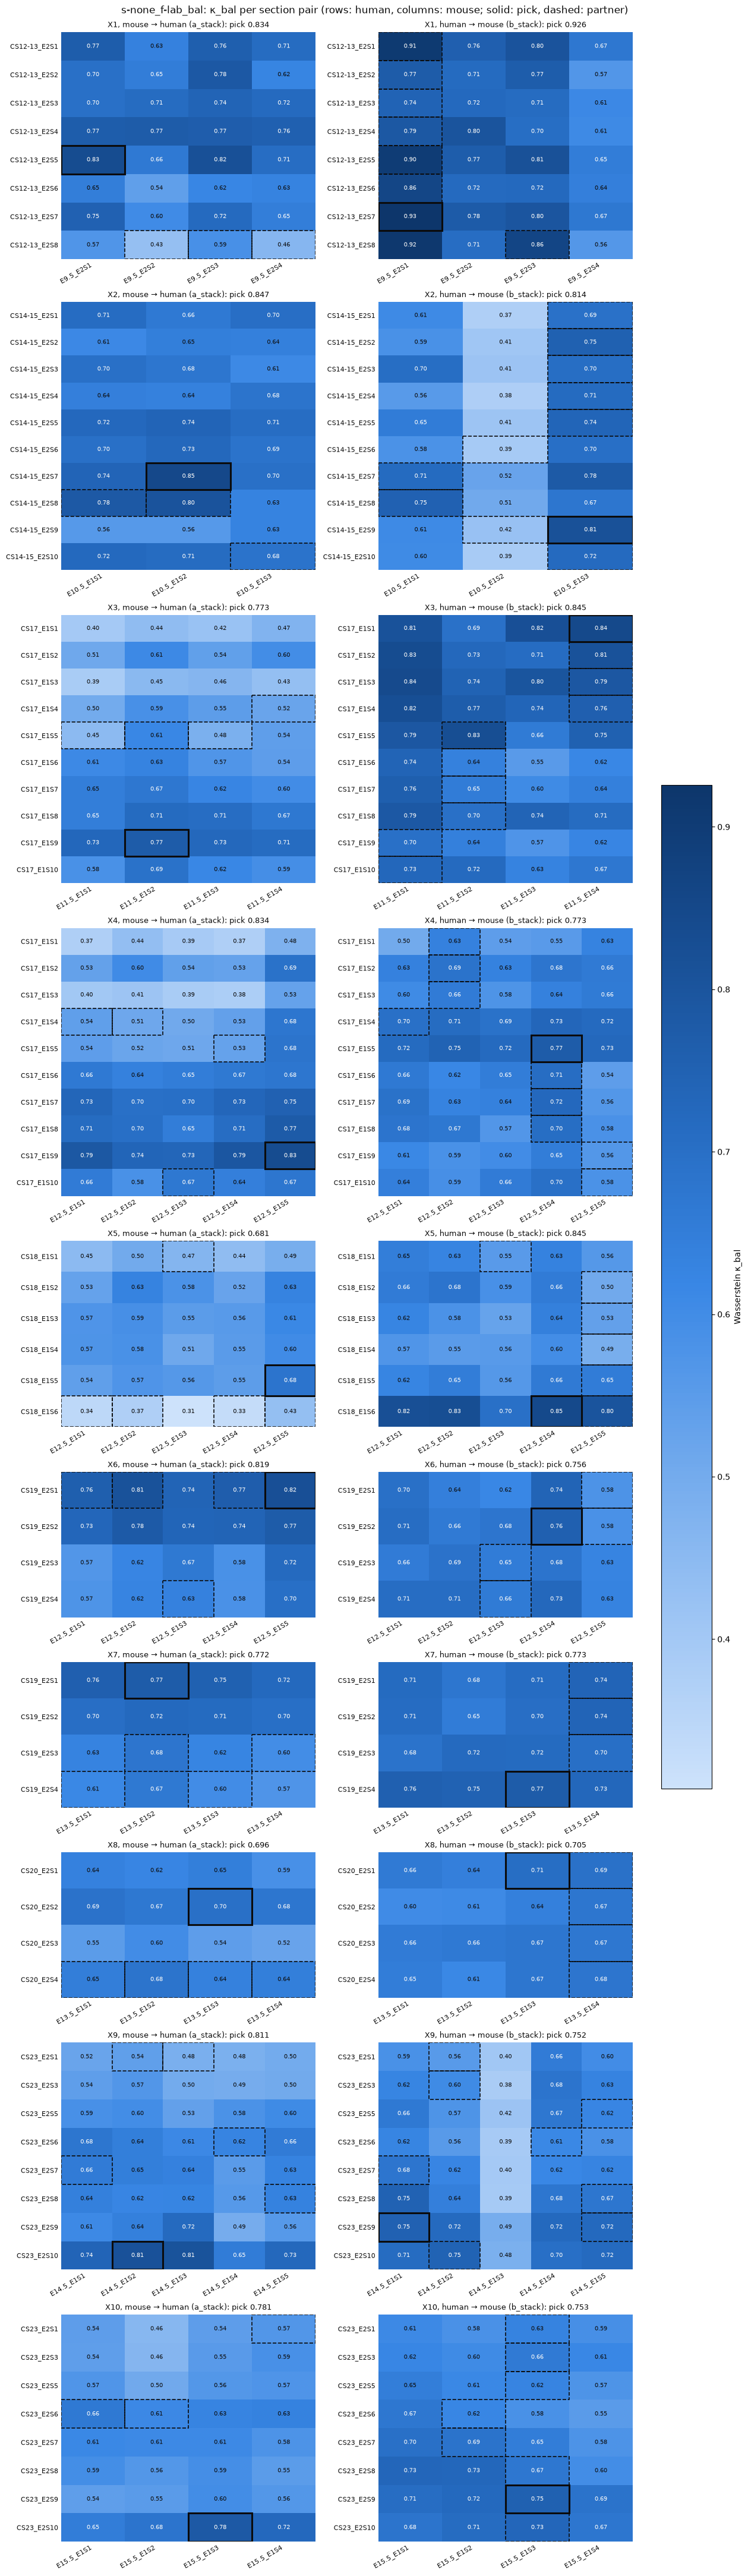

In [9]:
HUMAN, MOUSE = "#2a78d6", "#eb6834"               # categorical slots 1 and 2: the query's species
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95",
                                                 "#0d366b"])
SEQ.set_bad(SURFACE)
METRICS = {"kappa_bal": "κ_bal", "gene_r_heldout": "gene r, held-out genes", "gene_r_all": "gene r, all genes"}
W = scores[scores.run == W_RUN]
F = scores[scores.run != W_RUN]

lo, hi = W.kappa_bal.min(), W.kappa_bal.max()
mid = lo + 0.55 * (hi - lo)
heights = [len(SECTIONS[pid][0]) for pid in RUN_PAIRS]
ncol_max = max(len(SECTIONS[pid][1]) for pid in RUN_PAIRS)
fig, axes = plt.subplots(len(RUN_PAIRS), len(DIRS), squeeze=False, layout="constrained",
                         figsize=(len(DIRS) * (0.85 * ncol_max + 2), sum(0.42 * n + 1.3 for n in heights)),
                         gridspec_kw=dict(height_ratios=[0.42 * n + 1.3 for n in heights]))
for i, pid in enumerate(RUN_PAIRS):
    hs, ms = SECTIONS[pid]
    for j, d in enumerate(DIRS):
        ax = axes[i, j]
        s = W[(W.pair == pid) & (W.direction == d)]
        v = s.pivot_table(index="human", columns="mouse", values="kappa_bal").reindex(index=hs, columns=ms).to_numpy()
        im = ax.imshow(np.ma.masked_invalid(v), cmap=SEQ, vmin=lo, vmax=hi, aspect="auto")
        for (y, x), val in np.ndenumerate(v):
            if np.isfinite(val):
                ax.text(x, y, f"{val:.2f}", ha="center", va="center", fontsize=7, color=INK if val < mid else SURFACE)
        for _, r in s[s.partner].iterrows():
            ax.add_patch(Rectangle((ms.index(r.mouse) - 0.5, hs.index(r.human) - 0.5), 1, 1, fill=False, ec=INK,
                                   lw=1.2, ls="--"))
        h, m = PICKS[pid][d]
        ax.add_patch(Rectangle((ms.index(m) - 0.5, hs.index(h) - 0.5), 1, 1, fill=False, ec=INK, lw=2.2))
        ax.set_xticks(range(len(ms)), ms, fontsize=8, color=INK, rotation=30, ha="right")
        ax.set_yticks(range(len(hs)), hs, fontsize=8, color=INK)
        ax.tick_params(length=0)
        for sp_ in ax.spines.values():
            sp_.set_visible(False)
        ax.set_title(f"{pid}, {DIR_NAME[d]}: pick {s[s.best].kappa_bal.iloc[0]:.3f}", fontsize=9, color=INK)
fig.colorbar(im, ax=axes, shrink=0.4, label="Wasserstein κ_bal")
fig.suptitle(f"{W_RUN}: κ_bal per section pair (rows: human, columns: mouse; solid: pick, dashed: partner)",
             color=INK)
fig.savefig(OUT / f"{STEM}_wasserstein_kappa.png", dpi=150, bbox_inches="tight")
plt.show()

## The influence of the spatial term

Each score of the picked section pairs as a function of α: the Wasserstein coupling at α = 0 (open marker), FGW at each α of `ALPHAS`. One column per cross pair, one row per score (shared y within a row); the colour is the query's species (blue: human query, b_stack; orange: mouse query, a_stack). × marks an infeasible coupling (marginal error above `FEASIBLE_TOL`): its score is not comparable.

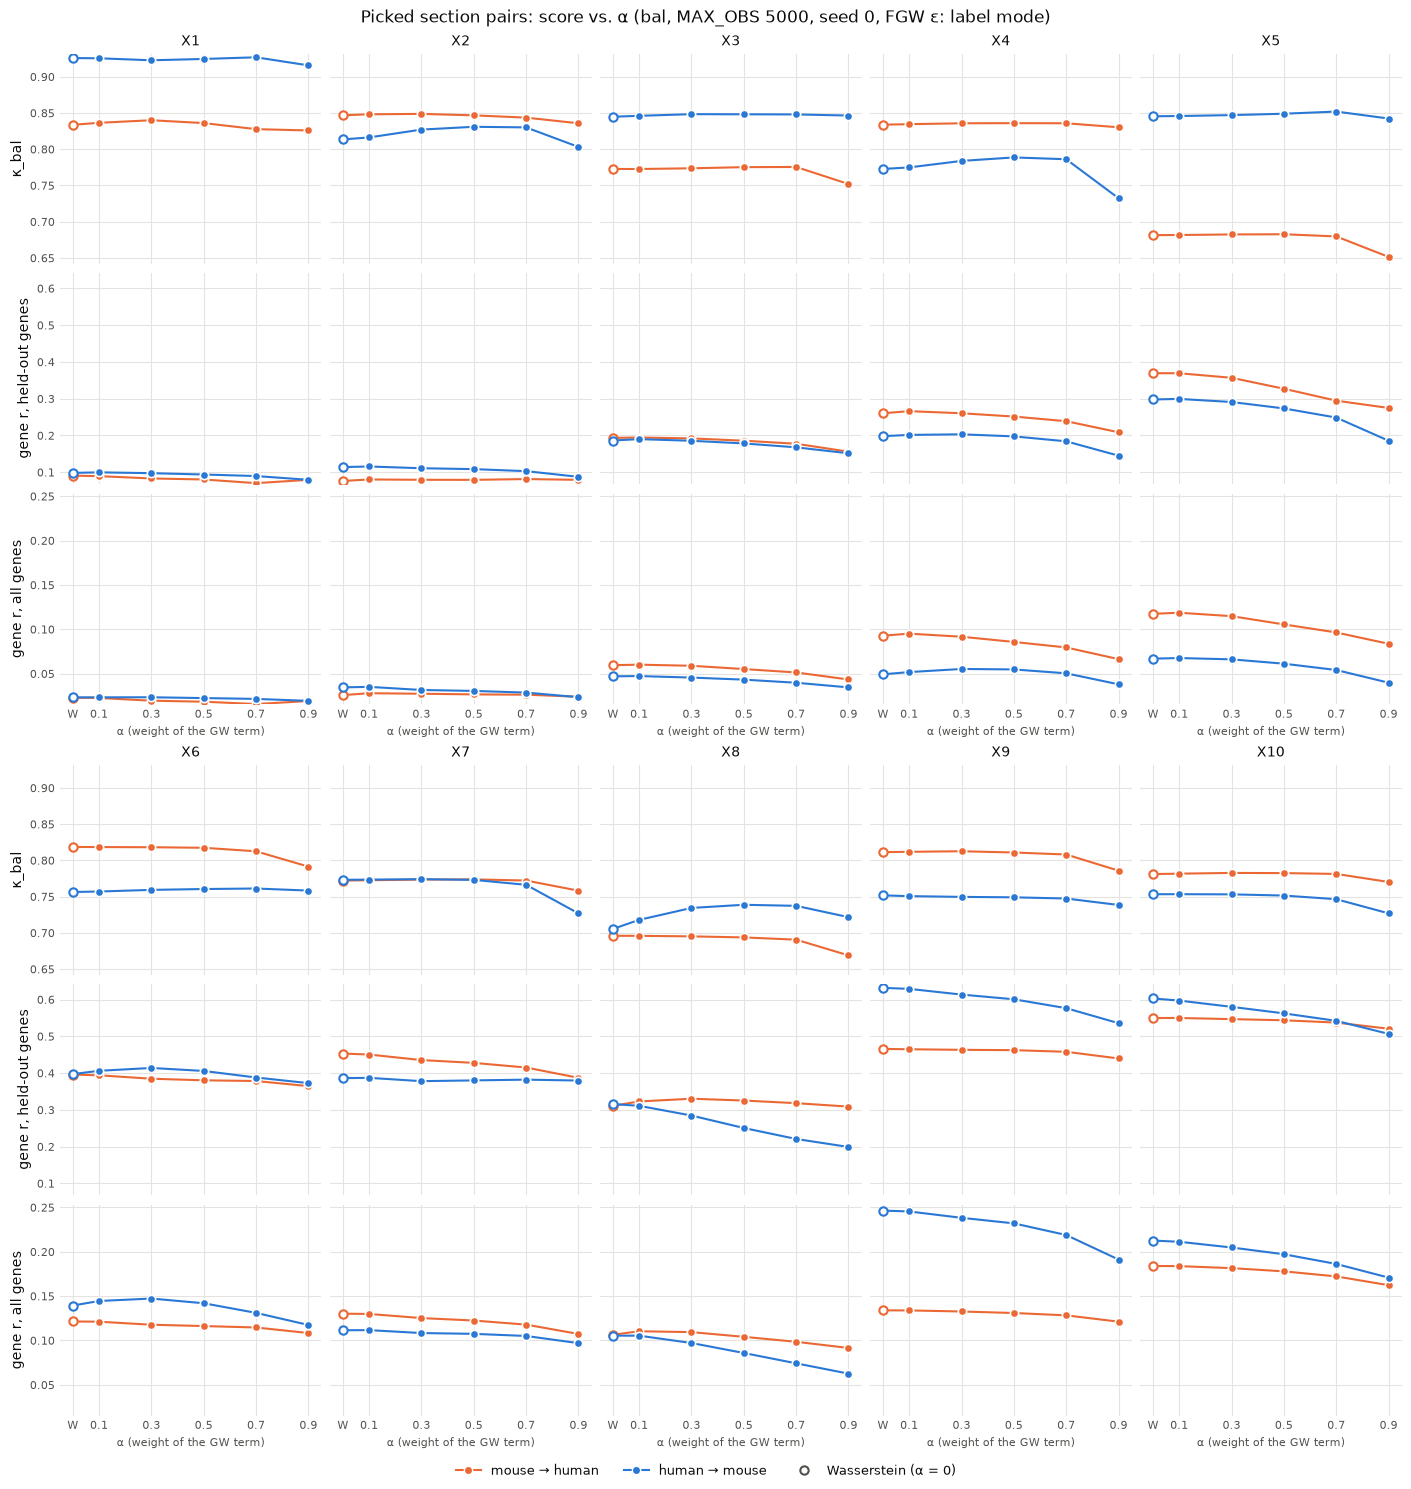

In [10]:
def curve(pid, d, col):
    """(alphas, values, feasible) of one direction's picked section pair: Wasserstein at alpha 0, then FGW at each
    alpha."""
    w = W[(W.pair == pid) & (W.direction == d) & W.best].iloc[0]
    f = F[(F.pair == pid) & (F.direction == d)].sort_values("alpha")
    return (np.r_[0.0, f.alpha.to_numpy()], np.r_[w[col], f[col].to_numpy()],
            np.r_[bool(w.feasible), f.feasible.to_numpy(dtype=bool)])


def mark_infeasible(ax, x, y, ok):
    if (~ok).any():
        ax.plot(x[~ok], y[~ok], "x", color=INK, ms=7, mew=1.6, zorder=4)


INFEASIBLE = Line2D([], [], ls="none", marker="x", ms=7, mew=1.6, color=INK,
                    label=f"infeasible (marginal error > {FEASIBLE_TOL:g})")


DIR_COLOR = {"b_stack": HUMAN, "a_stack": MOUSE}
DIR_SHORT = {"b_stack": "human → mouse", "a_stack": "mouse → human"}


def style(ax):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0, labelsize=8)
    for sp_ in ax.spines.values():
        sp_.set_visible(False)
    ax.set_xticks(np.r_[0.0, ALPHAS], ["W"] + [f"{a:g}" for a in ALPHAS])
    ax.set_xlim(-0.05, max(ALPHAS) + 0.05)


PANEL_COLS = 5                                    # at most this many pairs per row block, blocks balanced
nblocks = -(-len(RUN_PAIRS) // PANEL_COLS)
ncols = -(-len(RUN_PAIRS) // nblocks)
fig, axes = plt.subplots(len(METRICS) * nblocks, ncols, squeeze=False, sharex=True,
                         figsize=(2.6 * ncols + 1, 2.3 * len(METRICS) * nblocks + 1), layout="constrained")
for i in range(len(METRICS)):                    # empty slots of the last block
    for j in range(len(RUN_PAIRS) - (nblocks - 1) * ncols, ncols):
        axes[(nblocks - 1) * len(METRICS) + i, j].set_visible(False)
for i, (col, title) in enumerate(METRICS.items()):
    row_axes = []
    for k, pid in enumerate(RUN_PAIRS):
        b, j = divmod(k, ncols)
        ax = axes[b * len(METRICS) + i, j]
        row_axes.append(ax)
        for d in DIRS:
            x, y, ok = curve(pid, d, col)
            ax.plot(x, y, color=DIR_COLOR[d], lw=1.5, zorder=2)
            ax.plot(x[1:], y[1:], "o", color=DIR_COLOR[d], ms=6, mec=SURFACE, mew=1.2, zorder=3)
            ax.plot(x[:1], y[:1], "o", color=SURFACE, ms=6, mec=DIR_COLOR[d], mew=1.5, zorder=3)
            mark_infeasible(ax, x, y, ok)
        style(ax)
        if i == 0:
            ax.set_title(pid, color=INK, fontsize=10)
        if j == 0:
            ax.set_ylabel(title, color=INK)
        if i == len(METRICS) - 1:
            ax.set_xlabel("α (weight of the GW term)", color=MUTED, fontsize=8)
            ax.tick_params(labelbottom=True)      # the bottom row of every block, not only of the figure
    lo_, hi_ = min(a.get_ylim()[0] for a in row_axes), max(a.get_ylim()[1] for a in row_axes)
    for a in row_axes:                            # one y scale per score, across the row blocks
        a.set_ylim(lo_, hi_)
        if a.get_subplotspec().colspan.start > 0:
            a.tick_params(labelleft=False)
handles = [Line2D([], [], color=DIR_COLOR[d], lw=1.5, marker="o", ms=6, mec=SURFACE, label=DIR_SHORT[d])
           for d in DIRS]
handles.append(Line2D([], [], ls="none", marker="o", ms=6, color=SURFACE, mec=MUTED, mew=1.5,
                      label="Wasserstein (α = 0)"))
if not F.feasible.astype(bool).all() or not W.feasible.astype(bool).all():
    handles.append(INFEASIBLE)
fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), frameon=False, fontsize=9, labelcolor=INK)
fig.suptitle(f"Picked section pairs: score vs. α ({MARG}, MAX_OBS {MAX_OBS}, seed {SEED}, FGW ε: {EPS_MODE} mode)",
             color=INK)
fig.savefig(OUT / f"{STEM}_alpha_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

### Change from Wasserstein, all pairs together

The same curves minus their Wasserstein value, so every line starts at 0 and the pairs are compared on one axis: one panel per score and direction, one line per cross pair (labelled at its end; colour: the pair's stage, marker: the pair within it).

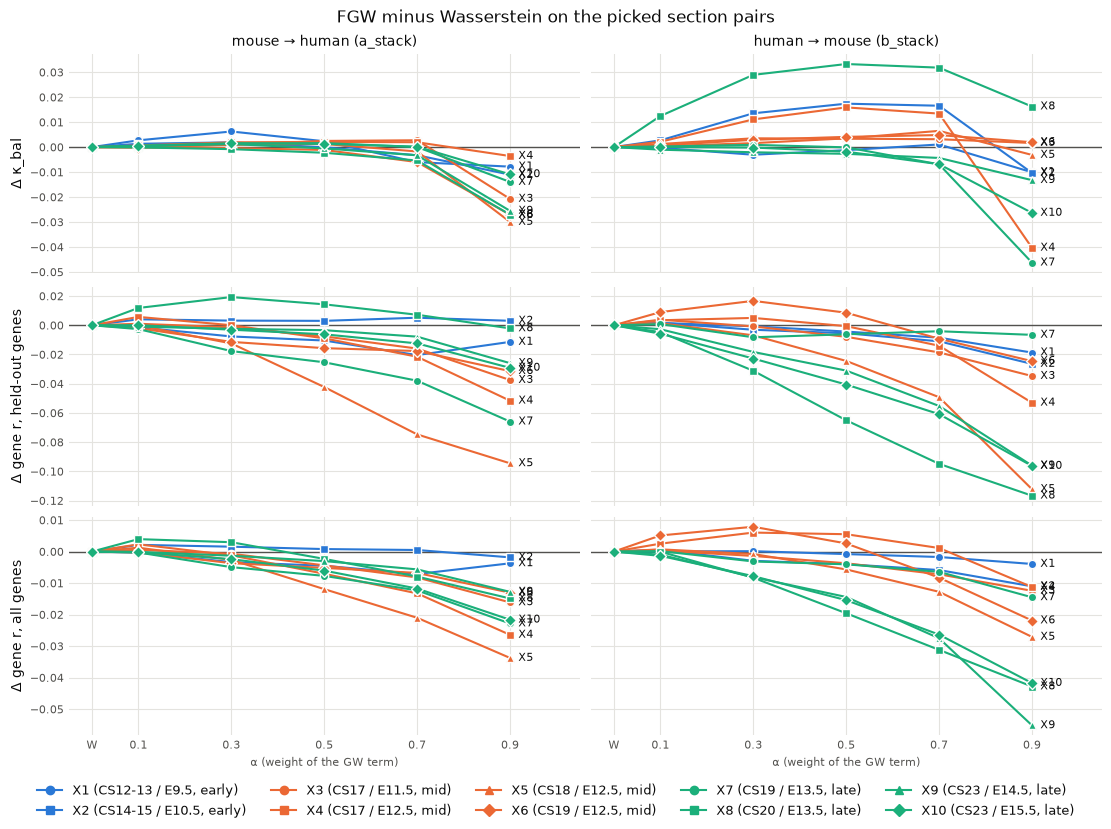

In [11]:
# ten pairs are too many hues: the colour is the pair's stage (series.yaml; categorical slots 1-3 in fixed order) and
# the marker tells the pairs of one stage apart, both fixed per pair (not per run); the line ends carry the pair id
STAGE_COLORS = {"early": "#2a78d6", "mid": "#eb6834", "late": "#1baf7a"}
STAGE_MARKERS = ["o", "s", "^", "D", "v", "P"]


def stage(pid):
    return SERIES.pairs[pid].stage.split()[0] if SERIES.pairs[pid].stage else "late"


CROSS = [pid for pid in SERIES.pairs if SERIES.pairs[pid].stage]
PCOL = {pid: STAGE_COLORS[stage(pid)] for pid in RUN_PAIRS}
PMARK = {pid: STAGE_MARKERS[[q for q in CROSS if stage(q) == stage(pid)].index(pid) % len(STAGE_MARKERS)]
         if pid in CROSS else "o" for pid in RUN_PAIRS}

fig, axes = plt.subplots(len(METRICS), len(DIRS), squeeze=False, sharex=True, sharey="row",
                         figsize=(5.2 * len(DIRS) + 0.6, 2.4 * len(METRICS) + 1), layout="constrained")
for i, (col, title) in enumerate(METRICS.items()):
    for j, d in enumerate(DIRS):
        ax = axes[i, j]
        ax.axhline(0, color=MUTED, lw=1, zorder=1)
        for pid in RUN_PAIRS:
            x, y, ok = curve(pid, d, col)
            ax.plot(x, y - y[0], color=PCOL[pid], lw=1.5, marker=PMARK[pid], ms=6, mec=SURFACE, mew=1, zorder=2)
            mark_infeasible(ax, x, y - y[0], ok)
            ax.annotate(pid, (x[-1], y[-1] - y[0]), xytext=(6, 0), textcoords="offset points", va="center",
                        fontsize=8, color=INK)
        style(ax)
        ax.set_xlim(-0.05, max(ALPHAS) + 0.15)
        if i == 0:
            ax.set_title(DIR_NAME[d], color=INK, fontsize=10)
        if j == 0:
            ax.set_ylabel(f"Δ {title}", color=INK)
        if i == len(METRICS) - 1:
            ax.set_xlabel("α (weight of the GW term)", color=MUTED, fontsize=8)
handles = [Line2D([], [], color=PCOL[pid], lw=1.5, marker=PMARK[pid], ms=6,
                  label=f"{pid} ({SERIES.pairs[pid].a.stage} / {SERIES.pairs[pid].b.stage}, {stage(pid)})")
           for pid in RUN_PAIRS]
if not F.feasible.astype(bool).all():
    handles.append(INFEASIBLE)
fig.legend(handles=handles,
           loc="outside lower center", ncol=min(len(RUN_PAIRS), 5), frameon=False, fontsize=9, labelcolor=INK)
fig.suptitle("FGW minus Wasserstein on the picked section pairs", color=INK)
fig.savefig(OUT / f"{STEM}_alpha_sweep_delta.png", dpi=150, bbox_inches="tight")
plt.show()

### The numbers

Per pair and direction, the picked section pair (query → target, `partner`: the target is the query's partner section) and each score of Wasserstein (`W`) and FGW at each α; last, the marginal error of every coupling (above `FEASIBLE_TOL`: infeasible).

In [12]:
picked = W[W.best].set_index(["pair", "direction"])
for col, title in METRICS.items():
    t = F.pivot_table(index=["pair", "direction"], columns="alpha", values=col)
    t.columns = [f"α {a:g}" for a in t.columns]
    t.insert(0, "W", picked[col])
    t.insert(0, "partner", picked.partner)
    t.insert(0, "query → target", picked["query"] + " → " + picked["target"])
    print(f"{title}\n{t.round(3).to_string()}\n")
t = F.pivot_table(index=["pair", "direction"], columns="alpha", values="marg_err")
t.columns = [f"α {a:g}" for a in t.columns]
t.insert(0, "W", picked.marg_err)
print(f"marginal error (L1; infeasible above {FEASIBLE_TOL:g})\n{t.map(lambda v: f'{v:.1e}').to_string()}")

κ_bal
                           query → target  partner      W  α 0.1  α 0.3  α 0.5  α 0.7  α 0.9
pair direction                                                                              
X1   a_stack     E9.5_E2S1 → CS12-13_E2S5     True  0.834  0.836  0.840  0.836  0.828  0.826
     b_stack     CS12-13_E2S7 → E9.5_E2S1     True  0.926  0.925  0.923  0.925  0.927  0.916
X10  a_stack      E15.5_E1S3 → CS23_E2S10     True  0.781  0.782  0.783  0.782  0.781  0.770
     b_stack       CS23_E2S9 → E15.5_E1S3     True  0.753  0.753  0.753  0.751  0.746  0.727
X2   a_stack    E10.5_E1S2 → CS14-15_E2S7    False  0.847  0.848  0.849  0.847  0.844  0.836
     b_stack    CS14-15_E2S9 → E10.5_E1S3    False  0.814  0.816  0.827  0.831  0.830  0.803
X3   a_stack       E11.5_E1S2 → CS17_E1S9    False  0.773  0.773  0.774  0.775  0.776  0.752
     b_stack       CS17_E1S1 → E11.5_E1S4     True  0.845  0.846  0.848  0.848  0.848  0.846
X4   a_stack       E12.5_E1S5 → CS17_E1S9     True  0.834  0.835

### Check against `label_alignment.ipynb`

Where `label_alignment.ipynb` has scored a pair at the same seed, `MAX_OBS` and marginals (`<root>/diag/label_alignment/<PAIR>_seed<SEED>_n<RES>_<MARG>.csv`), its rows for the same run, direction and section pair must agree with these (same cost, solver and ε), provided both ran at the same `INNER_TOL` and its FGW run used an α of `ALPHAS`.

In [13]:
ORIG = root / "diag" / "label_alignment"
for pid in RUN_PAIRS:
    path = ORIG / f"{pid}_seed{SEED}_n{RES}_{MARG}.csv"
    if not path.exists():
        print(f"{pid}: no {path.name}, skipped")
        continue
    keys = ["run", "direction", "query", "target"]
    both = scores[scores.pair == pid].merge(pd.read_csv(path), on=keys, suffixes=("", "_orig"))
    for run, g in both.groupby("run", sort=False):
        diffs = ", ".join(f"{c} {np.nanmax(np.abs(g[c] - g[c + '_orig'])):.1e}" for c in METRICS)
        print(f"{pid} {run}: {len(g)} rows in common, max |difference| {diffs}")

X1: no X1_seed0_n5000_bal.csv, skipped
X2: no X2_seed0_n5000_bal.csv, skipped
X3: no X3_seed0_n5000_bal.csv, skipped
X4: no X4_seed0_n5000_bal.csv, skipped
X5: no X5_seed0_n5000_bal.csv, skipped
X6: no X6_seed0_n5000_bal.csv, skipped
X7: no X7_seed0_n5000_bal.csv, skipped
X8: no X8_seed0_n5000_bal.csv, skipped
X9: no X9_seed0_n5000_bal.csv, skipped
X10: no X10_seed0_n5000_bal.csv, skipped


## How to read the results

- **Score against α:** α weighs space against the labels (in `label` mode at a fixed label entropy). With a cross cost this close to perfect, the GW term mostly pulls the coupling away from the labels. Wasserstein is the floor of the label cost for every feasible coupling, but not the ceiling of κ_bal: κ_bal is organ-balanced and weights query tiles by their bins, so a feasible FGW coupling can raise it by moving the errors that balanced marginals force onto other organs (`demos/label_alignment_diagnostic.py`). Gains of an infeasible coupling (×) don't count. A flat curve means the two sections' geometries agree with their organ layout; the α where it starts to fall is how much spatial weight the pair tolerates. A steep fall means space and labels disagree (different cut angle, depth or orientation).
- **The pick:** the section pair with the highest Wasserstein κ_bal is the one whose organs overlap best, not necessarily the partner section; the heatmaps show how clear the pick is.
- **The two directions:** under balanced marginals a section pair picked by both directions shares one coupling, and the two curves differ only in which side is scored.
- **Gene r:** no genes enter a label coupling, so gene r is the non-circular score here; it favours spread-out couplings (doc, section 6), so read it together with κ_bal.

## Gene correlations

So far gene r was only a mean per coupling; this section looks at it **per gene**, on the picked section pairs, at Wasserstein (W, α = 0) and at each α of `ALPHAS`.

**Computing it:** the couplings aren't saved, so the next cell solves the picked section pairs again (no new pick). It needs the bench caches and a GPU, about 120 solves in all, and saves after every pair to `<STEM>_gene_r.parquet` (one row per gene, coupling and direction) and `<STEM>_gene_cross.npz`. Pairs already in those files are skipped, so with the files copied to the local bench root the plots run without a GPU. Without the files or the caches this section prints a hint and skips its plots.

**Terms:**
- **expressed:** detected in at least `MIN_DETECT` of the tiles of both sections. Below that a gene has nothing to correlate, so "no correlation" would only mean "sparse". Everything except the "all genes" curves below uses expressed genes only.
- **null bound:** the 99th percentile of |r| of the expressed genes with the target's spots shuffled, per coupling. Below it, r is not distinguishable from chance.
- **Two directions:** each pair has one picked section pair per direction. Unless a table says otherwise, a gene's r in a pair is its mean over the directions in which it is expressed.
- **non-ortholog pairs:** a human gene against the mouse ortholog of a *different* gene, among the `N_CROSS` most variable genes of the section pair. The caches hold 1:1 orthologs only, so paralogs, 1:many and species-specific genes aren't covered.

In [14]:
MIN_DETECT = 0.05                # share of tiles a gene must be detected in, in both sections, to count as expressed
MIN_PAIRS = 8                    # gene rankings across pairs: expressed in at least this many pairs
TOP_CROSS = 200                  # strongest non-ortholog gene pairs kept per coupling
TOP_TIME = 15                    # genes per list of the time analysis
R_BINS = np.linspace(-1, 1, 201)
ALPHAS_ALL = (0.0, *ALPHAS)      # 0: Wasserstein
GENE_R, GENE_CROSS = OUT / f"{STEM}_gene_r.parquet", OUT / f"{STEM}_gene_cross.npz"
h2m = dict(zip(ortho.human, ortho.mouse))


def alpha_name(a):
    return "W" if a == 0 else f"α {a:g}"


def cross_r(Pq, Yq, Yt):
    "Pearson r over the query's spots of every query gene against every target gene transported through Pq."
    def z(X):
        Xc = X.astype(np.float64) - X.mean(0)
        norm = np.sqrt((Xc ** 2).sum(0))
        return Xc / np.where(norm > 0, norm, 1)
    Pn = np.asarray(Pq, dtype=np.float32)
    return z(Yq).T @ z((Pn / (Pn.sum(1, keepdims=True) + 1e-30)) @ Yt)


def cross_summary(C, C0, genes, d):
    "What is kept of the cross-gene matrices C (shuffled: C0), rows query genes: histograms, own-ortholog share, top."
    n, off = len(C), ~np.eye(len(C), dtype=bool)
    r_own = np.diag(C)
    hist = lambda v: np.histogram(v, R_BINS)[0]
    summary = dict(own_best=(C.argmax(1) == np.arange(n)).mean(), diag=hist(r_own), off=hist(C[off]), off0=hist(C0[off]))
    Coff = np.where(off, C, -np.inf)
    i, j = np.unravel_index(np.argpartition(Coff.ravel(), -TOP_CROSS)[-TOP_CROSS:], C.shape)
    hu, mo = (i, j) if d == "b_stack" else (j, i)
    top = pd.DataFrame(dict(human=genes[hu], mouse=[h2m[g] for g in genes[mo]], r=C[i, j], r_human_own=r_own[hu],
                            r_mouse_own=r_own[mo]))
    return summary, top


def picked_couplings(task, d, p):
    "(alpha, human x mouse coupling) of direction d's picked section pair: Wasserstein (alpha 0), then FGW at each alpha."
    h, m = PICKS[task.pair.id][d]
    sh, sm, tt = task.data["a"][h], task.data["b"][m], taus(d)
    Ml = label_cost(sh.comp, sm.comp)
    yield 0.0, ot_linear(Ml, tt[0], p, tau_b=tt[1])[0]
    Dh, Dm = dist(task, sh), dist(task, sm)
    for alpha in ALPHAS:
        yield alpha, solve_fgw(Ml, Dh, Dm, alpha, *tt, p)[0]


def gene_correlations(pid):
    "The rows of one pair: (per gene, per coupling summary with its histograms, top non-ortholog gene pairs)."
    task = Task(cfg, PIPELINE, SERIES.pairs[pid], SEED, root)
    p = fgw_params(task)
    H, Mo = task.data["a"], task.data["b"]
    held = np.load(prepare.feature_file(root, pid, SEED, FH), allow_pickle=False)["eval_a"].astype(str)
    G, genes = load_genes({**H, **Mo})
    gene_rows, sum_rows, top_rows = [], [], []
    for d in DIRS:
        h, m = PICKS[pid][d]
        q, t = (m, h) if d == "a_stack" else (h, m)
        Yq, Yt = G[q].toarray(), G[t].toarray()
        det = np.minimum((Yq > 0).mean(0), (Yt > 0).mean(0)).astype(np.float32)
        cg = cs.pick_eval_genes(Yq, Yt, genes.to_numpy(str), N_CROSS)
        cols = genes.get_indexer(cg)
        perm = np.random.default_rng(SEED).permutation(len(Yt))     # the permutation of coexpression_all
        for alpha, P in picked_couplings(task, d, p):
            check(P, f"{pid} {d} alpha {alpha}")
            Pq = P if d == "b_stack" else P.T
            r, r0 = coexpression_all(Pq, Yq, Yt)
            key = dict(pair=pid, direction=d, alpha=alpha)
            gene_rows.append(pd.DataFrame(dict(key, gene=genes, held_out=genes.isin(held), det=det,
                                               r=r.astype(np.float32), r0=r0.astype(np.float32))))
            s, top = cross_summary(cross_r(Pq, Yq[:, cols], Yt[:, cols]), cross_r(Pq, Yq[:, cols], Yt[perm][:, cols]),
                                   cg, d)
            sum_rows.append(dict(key, **s))
            top_rows.append(top.assign(**key))
            print(f"  {pid} {d} {alpha_name(alpha)}: mean r all {np.nanmean(r):.3f}, own ortholog best {s['own_best']:.0%}")
    return pd.concat(gene_rows, ignore_index=True), pd.DataFrame(sum_rows), pd.concat(top_rows, ignore_index=True)


def save_gene_tables(genes_, sums, tops):
    genes_.to_parquet(GENE_R)
    arr = {f"top|{c}": tops[c].to_numpy(dtype=str if c in ("human", "mouse", "pair", "direction") else None) for c in tops}
    arr.update({f"sum|{c}": np.stack(sums[c]) if c in ("diag", "off", "off0") else
                sums[c].to_numpy(dtype=str if c in ("pair", "direction") else None) for c in sums})
    np.savez_compressed(GENE_CROSS, **arr)


def load_gene_tables():
    z = np.load(GENE_CROSS, allow_pickle=False)
    table = lambda kind: {k.split("|")[1]: z[k] for k in z.files if k.startswith(f"{kind}|")}
    sums = table("sum")
    sums = pd.DataFrame({c: list(v) if v.ndim > 1 else v for c, v in sums.items()})
    return pd.read_parquet(GENE_R), sums, pd.DataFrame(table("top"))


def check_gene_means(genes_, tol=1e-2):
    "The recomputed mean r must match the scores of the original run."
    run = genes_.alpha.map(lambda a: W_RUN if a == 0 else fgw_run(a))
    g = genes_.assign(run=run.astype(str))
    keys = ["pair", "direction", "run"]
    m = g.groupby(keys, observed=True).r.mean().rename("all").to_frame()
    m["heldout"] = g[g.held_out].groupby(keys, observed=True).r.mean()
    m = m.join(scores[scores.best].astype({"pair": str}).set_index(keys)[["r_all", "r_heldout"]])
    diff = max((m["all"] - m.r_all).abs().max(), (m.heldout - m.r_heldout).abs().max())
    print(f"recomputed mean r against the scores of the run: max |difference| {diff:.1e} over {len(m)} couplings")
    assert diff < tol, f"the re-solved couplings disagree with the stored scores ({diff:.3f})"


# the cross matrix's diagonal is coexpression_all's r; two identical sections with an identity coupling match each
# gene to itself, and the top gene pairs never hold a gene and its own ortholog
rng = np.random.default_rng(2)
Yq, Yt, Pt = rng.random((60, 30), dtype=np.float32), rng.random((40, 30), dtype=np.float32), rng.random((60, 40))
assert np.allclose(np.diag(cross_r(Pt, Yq, Yt)), coexpression_all(Pt, Yq, Yt)[0], atol=1e-5)
tg = pd.Index(ortho.human[:30]).to_numpy(str)
Ci = cross_r(np.eye(60), Yq, Yq)
si, ti = cross_summary(Ci, Ci, tg, "b_stack")
assert si["own_best"] == 1 and len(ti) == TOP_CROSS and (ti.human != ti.mouse.map(dict(zip(ortho.mouse, ortho.human)))).all()
del Yq, Yt, Pt, Ci, si, ti, tg

GENES, CROSS_SUM, CROSS_TOP = load_gene_tables() if GENE_R.exists() and GENE_CROSS.exists() else (None, None, None)
done = set() if GENES is None else set(GENES.pair.astype(str))
absent = {pid: m for pid in RUN_PAIRS if pid not in done and (m := missing_inputs(SERIES.pairs[pid]))}
for pid in RUN_PAIRS:
    if pid in done or pid in absent:
        continue
    t0 = time.perf_counter()
    g_, s_, t_ = gene_correlations(pid)
    GENES = g_ if GENES is None else pd.concat([GENES, g_], ignore_index=True)
    CROSS_SUM = s_ if CROSS_SUM is None else pd.concat([CROSS_SUM, s_], ignore_index=True)
    CROSS_TOP = t_ if CROSS_TOP is None else pd.concat([CROSS_TOP, t_], ignore_index=True)
    save_gene_tables(GENES, CROSS_SUM, CROSS_TOP)
    print(f"{pid} done in {time.perf_counter() - t0:.0f} s")
if absent:
    print(f"no gene correlations for {', '.join(absent)}: their caches are missing here. Run this notebook where they "
          f"are, or copy {GENE_R.name} and {GENE_CROSS.name} to {OUT}")
GENES_READY = GENES is not None
if GENES_READY:
    check_gene_means(GENES)
    GENE_PAIRS = [pid for pid in RUN_PAIRS if pid in set(GENES.pair.astype(str))]
    GENES = GENES.assign(expressed=GENES.det >= MIN_DETECT)
    # null bound per coupling, on the expressed genes
    EXPR = GENES[GENES.expressed].copy()
    EXPR["bound"] = EXPR.groupby(["pair", "direction", "alpha"], observed=True).r0.transform(
        lambda v: np.nanquantile(np.abs(v), 0.99))
    EXPR["above"] = EXPR.r.abs() > EXPR.bound
    # a gene's r in a pair and at an alpha: the mean over the directions in which it is expressed
    GENE_MEAN = EXPR.groupby(["pair", "alpha", "gene"], observed=True, as_index=False).agg(
        r=("r", "mean"), held_out=("held_out", "max"), above=("above", "mean"))
    GENE_MEAN["pair"] = GENE_MEAN.pair.astype(str)
    GENE_MEAN["gene"] = GENE_MEAN.gene.astype(str)
    print(f"{GENES.gene.nunique()} genes, {EXPR.gene.nunique()} expressed in at least one pair, pairs {', '.join(GENE_PAIRS)}")

recomputed mean r against the scores of the run: max |difference| 3.4e-05 over 120 couplings
15115 genes, 13192 expressed in at least one pair, pairs X1, X2, X3, X4, X5, X6, X7, X8, X9, X10


### The distribution of gene r: held-out and all genes

Gene r at W, per cross pair. *all genes* has every gene of the pair and *expressed* only those above `MIN_DETECT`; the spike of *all genes* at 0 is the sparse genes. *shuffled* is the expressed genes with the target's spots shuffled, the distribution of chance.

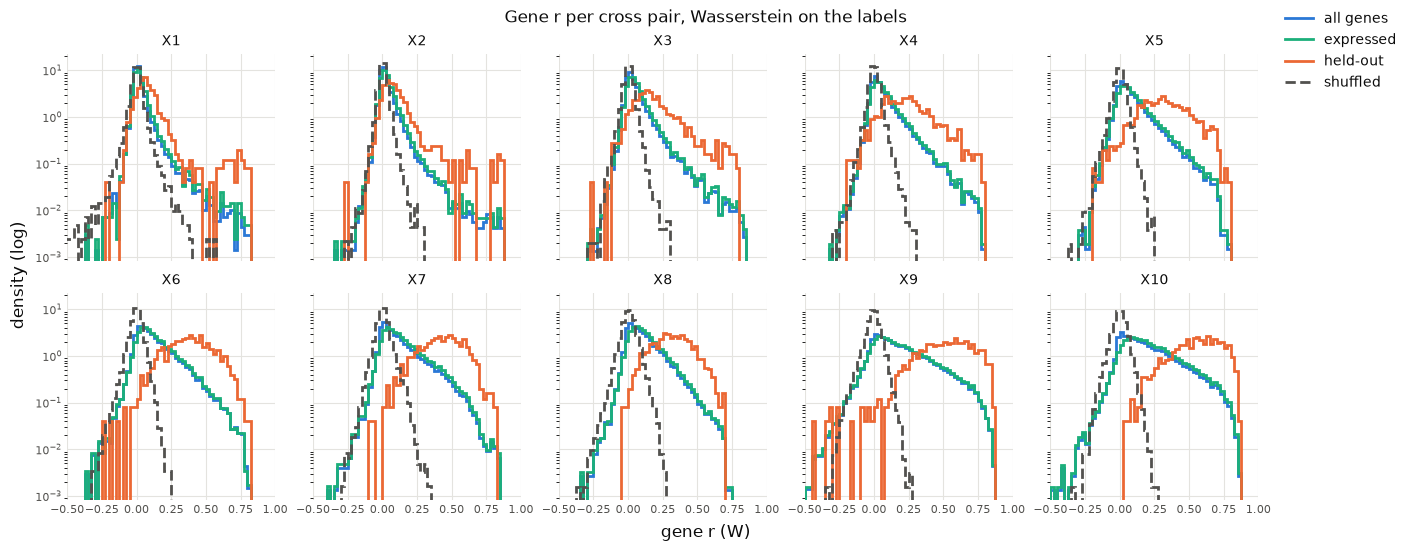

      genes  expressed  median_all  median_expressed  median_heldout  median_shuffled  above_null_expressed  above_null_heldout
pair                                                                                                                           
X1    13791       8292       0.010             0.015           0.066           -0.001                 0.042               0.130
X2    14155       9227       0.015             0.026           0.074            0.002                 0.129               0.362
X3    14482      10523       0.029             0.043           0.157            0.000                 0.192               0.655
X4    13188      11000       0.040             0.051           0.223           -0.001                 0.233               0.739
X5    13274      10885       0.055             0.072           0.311           -0.002                 0.297               0.875
X6    13326      11849       0.091             0.105           0.384           -0.002                 0.

In [15]:
GENE_COLORS = {"all genes": "#2a78d6", "expressed": "#1baf7a", "held-out": "#eb6834", "shuffled": MUTED}
PLOT_BINS = np.linspace(-1, 1, 81)


def plain(ax):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0, labelsize=8)
    for sp_ in ax.spines.values():
        sp_.set_visible(False)


def pair_axes(pids, height=2.2, **kw):
    "One panel per pair, at most PANEL_COLS in a row; returns the figure and the {pair: axis}."
    nrow = -(-len(pids) // PANEL_COLS)
    fig, axes = plt.subplots(nrow, PANEL_COLS, squeeze=False, layout="constrained",
                             figsize=(2.6 * PANEL_COLS + 1, height * nrow + 1), **kw)
    for ax in axes.flat[len(pids):]:
        ax.set_visible(False)
    return fig, dict(zip(pids, axes.flat))


def show_distribution():
    W_ = GENES[GENES.alpha == 0]
    fig, axes = pair_axes(GENE_PAIRS, sharex=True, sharey=True)
    rows = []
    for pid, ax in axes.items():
        g = W_[W_.pair == pid]
        e = g[g.expressed]
        series = {"all genes": g.r, "expressed": e.r, "held-out": e[e.held_out].r, "shuffled": e.r0}
        for name, v in series.items():
            ax.hist(v.dropna(), PLOT_BINS, density=True, histtype="step", lw=2, color=GENE_COLORS[name],
                    ls="--" if name == "shuffled" else "-")
        plain(ax)
        ax.set_title(pid, color=INK, fontsize=10)
        ax.set_yscale("log")
        ax.set_xlim(-0.5, 1)
        ee = EXPR[(EXPR.pair == pid) & (EXPR.alpha == 0)]
        rows.append(dict(pair=pid, genes=g.gene.nunique(), expressed=e.gene.nunique(), median_all=g.r.median(),
                         median_expressed=e.r.median(), median_heldout=e[e.held_out].r.median(),
                         median_shuffled=e.r0.median(), above_null_expressed=ee.above.mean(),
                         above_null_heldout=ee[ee.held_out].above.mean()))
    fig.supxlabel("gene r (W)", color=INK)
    fig.supylabel("density (log)", color=INK)
    fig.legend(handles=[Line2D([], [], color=c, lw=2, ls="--" if n == "shuffled" else "-", label=n)
                        for n, c in GENE_COLORS.items()], loc="outside right upper", frameon=False,
               labelcolor=INK)
    fig.suptitle("Gene r per cross pair, Wasserstein on the labels", color=INK)
    fig.savefig(OUT / f"{STEM}_gene_r_hist.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(pd.DataFrame(rows).set_index("pair").round(3).to_string())


if GENES_READY:
    show_distribution()

### Which genes correlate heavily, which orthologs don't correlate at all

At W, among the genes expressed in at least `MIN_PAIRS` pairs: the highest median r over the pairs, the smallest median |r|, and the most negative median r. `under null`: the share of couplings (pair and direction) where |r| is below the null bound. A gene with a small median |r| and a high `under null` is an expressed ortholog whose pattern doesn't carry over.

In [16]:
def gene_rankings(n=30):
    W_ = GENE_MEAN[GENE_MEAN.alpha == 0]
    t = W_.groupby("gene").agg(n_pairs=("r", "size"), median_r=("r", "median"), min_r=("r", "min"), max_r=("r", "max"),
                               under_null=("above", lambda v: 1 - v.mean()), held_out_in=("held_out", "sum"))
    t = t[t.n_pairs >= min(MIN_PAIRS, len(GENE_PAIRS))].assign(abs_r=lambda d: d.median_r.abs())
    print(f"{len(t)} genes expressed in at least {min(MIN_PAIRS, len(GENE_PAIRS))} pairs\n")
    print(f"highest median r\n{t.sort_values('median_r', ascending=False).head(n).drop(columns='abs_r').round(3).to_string()}\n")
    print(f"smallest median |r|\n{t.sort_values('abs_r').head(n).drop(columns='abs_r').round(3).to_string()}\n")
    print(f"most negative median r\n{t.sort_values('median_r').head(n).drop(columns='abs_r').round(3).to_string()}")


if GENES_READY:
    gene_rankings()

10391 genes expressed in at least 8 pairs

highest median r
        n_pairs  median_r  min_r  max_r  under_null  held_out_in
gene                                                            
ALB           9     0.724  0.316  0.806       0.056            8
AHSG          8     0.713  0.621  0.811       0.000            2
APOA1         9     0.707  0.350  0.757       0.056            8
ITIH2        10     0.700  0.470  0.771       0.000            2
AFP          10     0.698  0.314  0.805       0.050            9
TUBA1A       10     0.696  0.216  0.815       0.050            6
FGB           9     0.695  0.593  0.753       0.000            0
FGG           8     0.691  0.625  0.719       0.000            0
RBP4         10     0.690  0.240  0.739       0.000            8
APOA2        10     0.688  0.329  0.782       0.050            9
TTN          10     0.687  0.596  0.787       0.000            9
FABP1         8     0.685  0.614  0.716       0.000            0
AMBP         10     0.682  0.4

### High correlation between genes that aren't orthologs

Among the `N_CROSS` most variable genes of each section pair, at W: the r of each gene with its own ortholog against its r with every other gene (*non-ortholog*), and the same with the target's spots shuffled. `own ortholog best`: the share of genes whose strongest partner in the other species is their own ortholog.

The tables list the strongest non-ortholog gene pairs (the `TOP_CROSS` strongest per coupling, so `n_pairs` counts only the pairs where it made that list). `r_human_own`, `r_mouse_own`: each gene's r with its own ortholog in the same coupling. Two marker genes of one organ correlate with each other's orthologs as well, so a high r alone says little; the second table holds the gene pairs that beat **both** own-ortholog values, where a gene's pattern fits the other gene's ortholog better than its own.

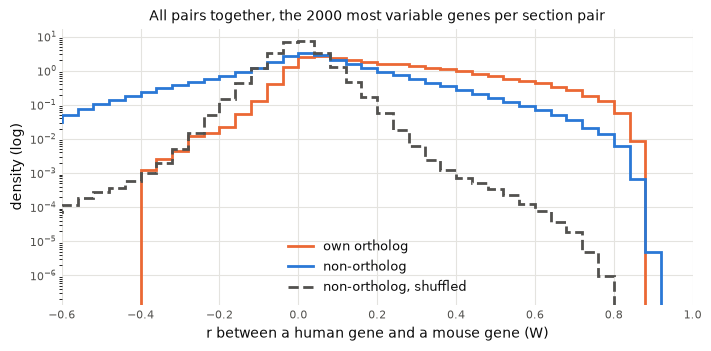

own ortholog best
alpha      W  α 0.1  α 0.3  α 0.5  α 0.7  α 0.9
pair                                           
X1     0.004  0.005  0.004  0.004  0.004  0.006
X2     0.008  0.006  0.008  0.005  0.006  0.007
X3     0.008  0.008  0.008  0.010  0.012  0.010
X4     0.012  0.010  0.012  0.013  0.013  0.010
X5     0.013  0.016  0.017  0.020  0.020  0.016
X6     0.027  0.028  0.030  0.033  0.036  0.036
X7     0.026  0.028  0.040  0.042  0.043  0.045
X8     0.016  0.015  0.015  0.016  0.014  0.017
X9     0.034  0.038  0.042  0.044  0.046  0.042
X10    0.034  0.039  0.040  0.045  0.045  0.044

strongest non-ortholog gene pairs
                  n_pairs  median_r  r_human_own  r_mouse_own
human    mouse                                               
NNAT     Copg2          1     0.885        0.838        0.284
APOC2    Afp            2     0.879        0.766        0.831
NNAT     Pak3           2     0.878        0.842        0.624
         Rnf152         1     0.877        0.838        0.413

In [17]:
def rebin(h, k=4):
    "Counts of R_BINS merged by k, as a density: (bin edges, density)."
    h = np.add.reduce(h[: len(h) // k * k].reshape(-1, k), axis=1)
    edges = R_BINS[::k][: len(h) + 1]
    return edges, h / max(h.sum(), 1) / (edges[1] - edges[0])


def cross_quantile(h, q):
    "Quantile q of a histogram over R_BINS."
    return R_BINS[1:][np.searchsorted(np.cumsum(h), q * h.sum())]


def show_cross(n=30):
    S0 = CROSS_SUM[CROSS_SUM.alpha == 0]
    fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
    for col, name, c, ls in (("diag", "own ortholog", GENE_COLORS["held-out"], "-"),
                             ("off", "non-ortholog", GENE_COLORS["all genes"], "-"),
                             ("off0", "non-ortholog, shuffled", MUTED, "--")):
        edges, dens = rebin(np.sum(np.stack(S0[col]), axis=0))
        ax.stairs(dens, edges, color=c, lw=2, ls=ls, label=name)
    plain(ax)
    ax.set_yscale("log")
    ax.set_xlim(-0.6, 1)
    ax.set_xlabel("r between a human gene and a mouse gene (W)", color=INK)
    ax.set_ylabel("density (log)", color=INK)
    ax.legend(frameon=False, labelcolor=INK, fontsize=9)
    ax.set_title(f"All pairs together, the {N_CROSS} most variable genes per section pair", color=INK, fontsize=10)
    fig.savefig(OUT / f"{STEM}_gene_cross_hist.png", dpi=150, bbox_inches="tight")
    plt.show()

    t = CROSS_SUM.assign(p99=[cross_quantile(h, 0.99) for h in CROSS_SUM.off])
    print("own ortholog best\n" + t.pivot_table(index="pair", columns="alpha", values="own_best").reindex(GENE_PAIRS)
          .rename(columns=alpha_name).round(3).to_string() + "\n")

    T = CROSS_TOP[CROSS_TOP.alpha == 0].assign(pair=lambda d: d.pair.astype(str))
    # a coupling's values of a gene pair; over the directions and the pairs: the median, and how many pairs have it
    agg = T.groupby(["human", "mouse"]).agg(n_pairs=("pair", "nunique"), median_r=("r", "median"),
                                            r_human_own=("r_human_own", "median"), r_mouse_own=("r_mouse_own", "median"))
    print(f"strongest non-ortholog gene pairs\n{agg.sort_values(['median_r'], ascending=False).head(n).round(3).to_string()}\n")
    print(f"most recurrent\n{agg.sort_values(['n_pairs', 'median_r'], ascending=False).head(n).round(3).to_string()}\n")
    beat = T[T.r > T[["r_human_own", "r_mouse_own"]].max(axis=1)]
    a = beat.assign(gap=beat.r - beat[["r_human_own", "r_mouse_own"]].max(axis=1)).groupby(["human", "mouse"]).agg(
        n_pairs=("pair", "nunique"), median_r=("r", "median"), r_human_own=("r_human_own", "median"),
        r_mouse_own=("r_mouse_own", "median"), median_gap=("gap", "median"))
    print(f"better than both own orthologs: {len(beat)} of {len(T)} rows\n"
          f"{a.sort_values(['median_gap'], ascending=False).head(n).round(3).to_string()}")


if GENES_READY:
    show_cross()

### Gene r with an increasing spatial constraint

The 10th, 50th and 90th percentile of gene r against α, per cross pair, for the expressed and the held-out genes (the band is the 10th to 90th percentile). The tables below give the share of expressed genes above the null bound, and the 99th percentile of the non-ortholog r.

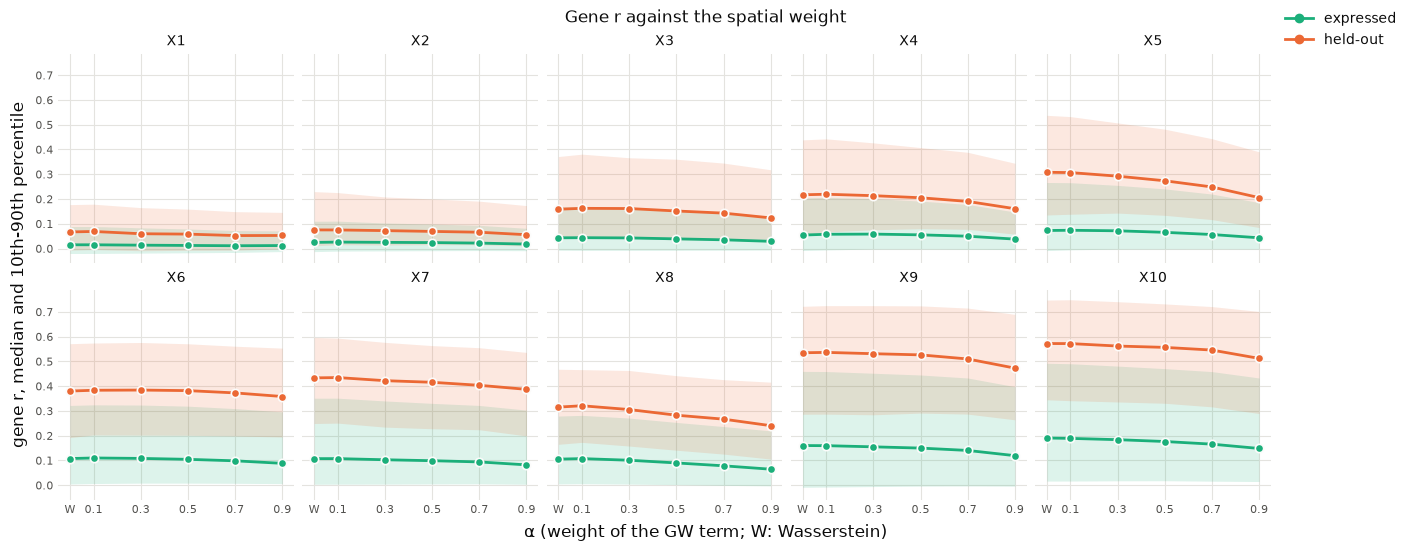

median r, expressed
alpha      W  α 0.1  α 0.3  α 0.5  α 0.7  α 0.9
pair                                           
X1     0.015  0.015  0.014  0.012  0.011  0.012
X2     0.025  0.026  0.025  0.024  0.022  0.018
X3     0.043  0.044  0.043  0.039  0.035  0.029
X4     0.054  0.058  0.058  0.055  0.050  0.038
X5     0.073  0.074  0.072  0.065  0.057  0.043
X6     0.108  0.110  0.108  0.104  0.098  0.088
X7     0.107  0.107  0.103  0.099  0.094  0.082
X8     0.105  0.107  0.101  0.090  0.078  0.065
X9     0.160  0.160  0.155  0.150  0.140  0.119
X10    0.191  0.189  0.184  0.176  0.166  0.148

share above the null bound, expressed
alpha      W  α 0.1  α 0.3  α 0.5  α 0.7  α 0.9
pair                                           
X1     0.042  0.044  0.049  0.053  0.066  0.093
X2     0.129  0.139  0.147  0.160  0.173  0.182
X3     0.192  0.197  0.202  0.213  0.227  0.243
X4     0.233  0.245  0.265  0.280  0.288  0.303
X5     0.297  0.300  0.311  0.324  0.337  0.338
X6     0.386  0.402  0.431  0

In [18]:
def show_alpha():
    fig, axes = pair_axes(GENE_PAIRS, sharex=True, sharey=True)
    x = np.asarray(ALPHAS_ALL)
    for pid, ax in axes.items():
        g = GENE_MEAN[GENE_MEAN.pair == pid]
        for name, sel in (("expressed", g), ("held-out", g[g.held_out])):
            q = sel.groupby("alpha").r.quantile([0.1, 0.5, 0.9]).unstack().reindex(x)
            ax.fill_between(x, q[0.1], q[0.9], color=GENE_COLORS[name], alpha=0.15, lw=0)
            ax.plot(x, q[0.5], color=GENE_COLORS[name], lw=2, marker="o", ms=6, mec=SURFACE, mew=1.2)
        style(ax)
        ax.set_title(pid, color=INK, fontsize=10)
    fig.supxlabel("α (weight of the GW term; W: Wasserstein)", color=INK)
    fig.supylabel("gene r, median and 10th-90th percentile", color=INK)
    fig.legend(handles=[Line2D([], [], color=GENE_COLORS[n], lw=2, marker="o", ms=6, label=n)
                        for n in ("expressed", "held-out")], loc="outside right upper", frameon=False,
               labelcolor=INK)
    fig.suptitle("Gene r against the spatial weight", color=INK)
    fig.savefig(OUT / f"{STEM}_gene_r_alpha.png", dpi=150, bbox_inches="tight")
    plt.show()

    tab = lambda t: t.reindex(GENE_PAIRS).rename(columns=alpha_name).round(3).to_string()
    print(f"median r, expressed\n{tab(GENE_MEAN.pivot_table(index='pair', columns='alpha', values='r', aggfunc='median'))}\n")
    print(f"share above the null bound, expressed\n{tab(EXPR.astype({'pair': str}).pivot_table(index='pair', columns='alpha', values='above'))}\n")
    p99 = CROSS_SUM.assign(p99=[cross_quantile(h, 0.99) for h in CROSS_SUM.off])
    print(f"99th percentile of the non-ortholog r\n{tab(p99.astype({'pair': str}).pivot_table(index='pair', columns='alpha', values='p99'))}")


if GENES_READY:
    show_alpha()

### Correlations over time: what persists and what changes

Over the cross pairs in stage order, among the genes expressed in at least `MIN_PAIRS` pairs, at W and at each α with the same ranking:
- **persistent:** the highest *minimum* r over the pairs;
- **rising / falling:** the largest and the most negative difference between the mean r of the `late` and the `early` pairs (the stages of `series.yaml`).

Each heatmap holds one α's lists (`TOP_TIME` genes each, split by the lines; empty cell: not expressed in that pair). The last table is the stability across α: how many of W's genes each α's lists keep, and the genes on a list at every α. Those are the temporal patterns that don't depend on the spatial weight.

/var/folders/yt/z9v0j0ld4ln5xtzsr2196m6w0000gn/T/ipykernel_88250/1952903261.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  R = R[R.notna().sum(1) >= min(MIN_PAIRS, len(GENE_PAIRS))]
/var/folders/yt/z9v0j0ld4ln5xtzsr2196m6w0000gn/T/ipykernel_88250/1952903261.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  delta = (R[late].mean(1) - R[early].mean(1)).dropna().sort_values()
/var/folders/yt/z9v0j0ld4ln5xtzsr2196m6w0000gn/T/ipykernel_88250/1952903261.py:11: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  delta = (R[late].mean(1) - R[early].mean(1)).dropna().sort_values()
/var/folders/yt/z9v0j0ld4ln5xtzsr2196m6w0000gn/T/ipykernel_88250/1952903261.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  R = R[R.notna().sum(1) >= min(MIN_PAIRS, len(GENE_PAIRS))]
/var/folders/yt/z9v0j0ld4ln5xtzsr2196m

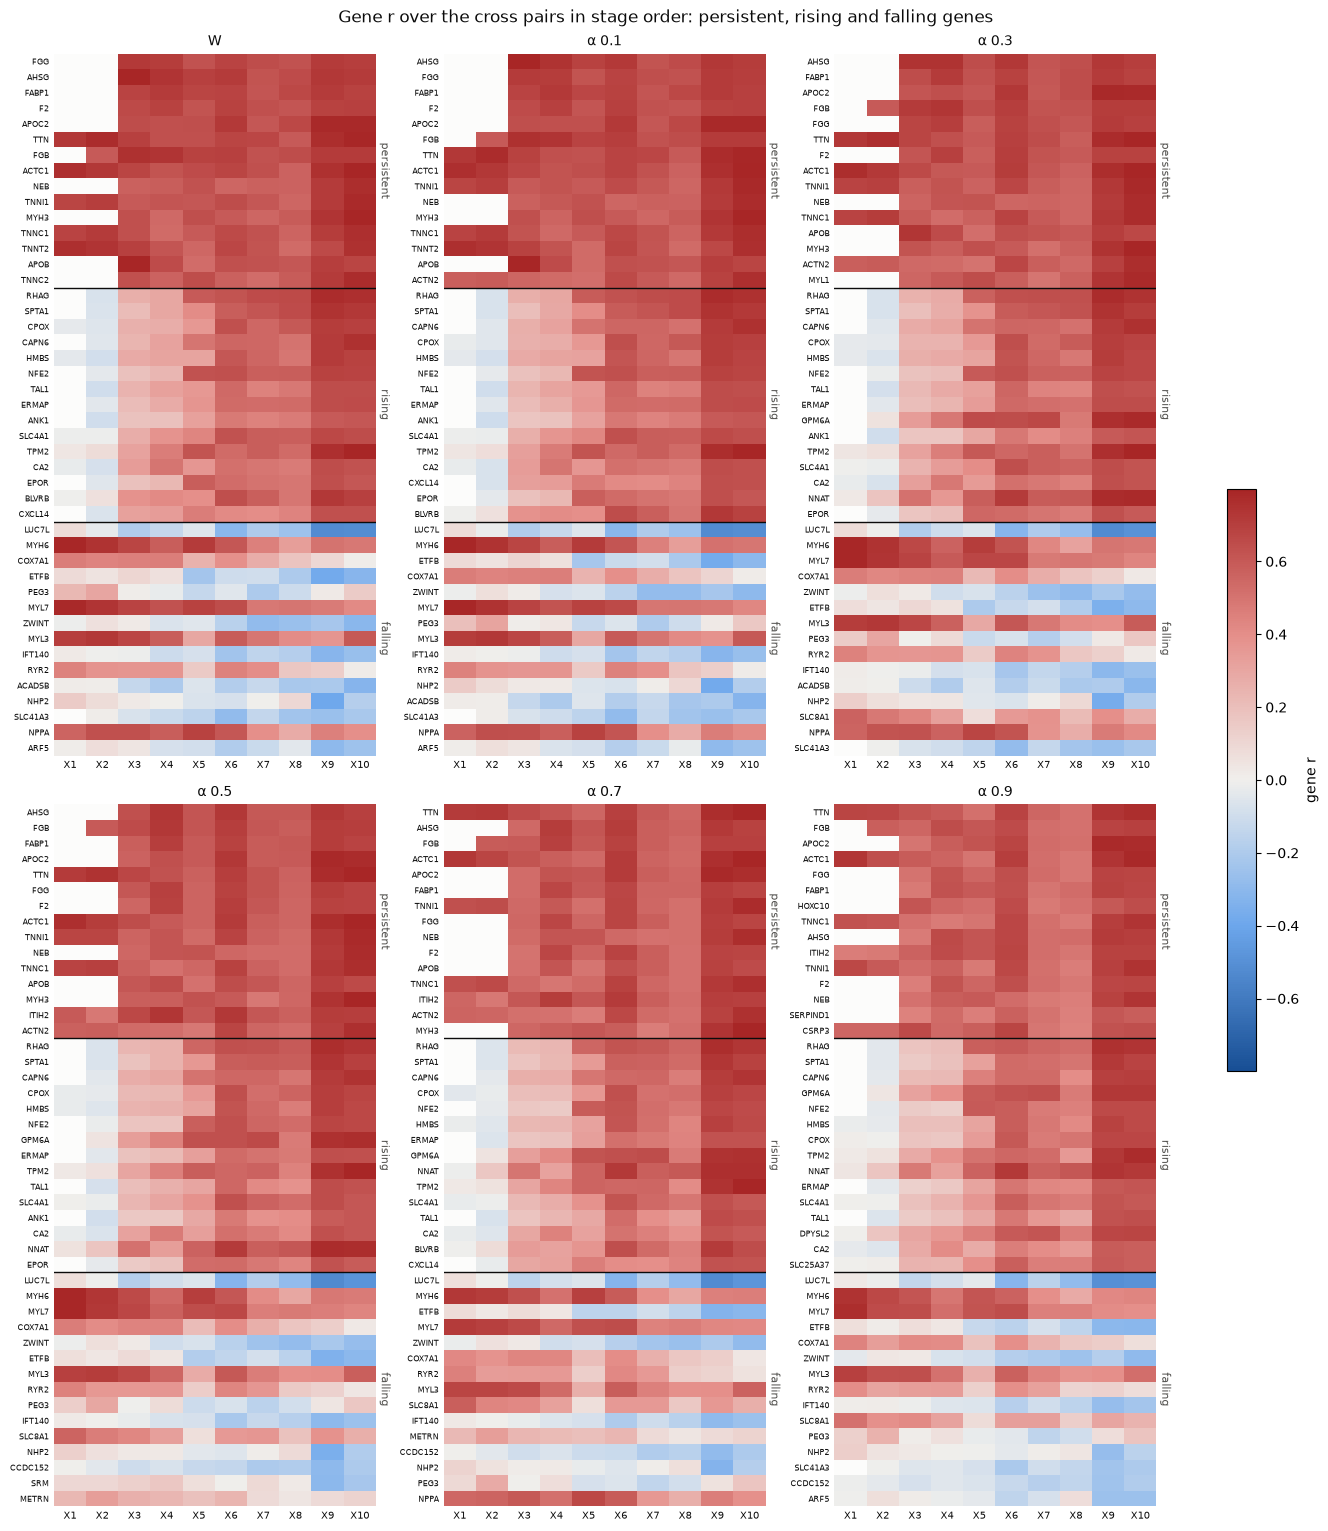

W
  persistent: FGG, AHSG, FABP1, F2, APOC2, TTN, FGB, ACTC1, NEB, TNNI1, MYH3, TNNC1, TNNT2, APOB, TNNC2
  rising: RHAG, SPTA1, CPOX, CAPN6, HMBS, NFE2, TAL1, ERMAP, ANK1, SLC4A1, TPM2, CA2, EPOR, BLVRB, CXCL14
  falling: LUC7L, MYH6, COX7A1, ETFB, PEG3, MYL7, ZWINT, MYL3, IFT140, RYR2, ACADSB, NHP2, SLC41A3, NPPA, ARF5
α 0.1
  persistent: AHSG, FGG, FABP1, F2, APOC2, FGB, TTN, ACTC1, TNNI1, NEB, MYH3, TNNC1, TNNT2, APOB, ACTN2
  rising: RHAG, SPTA1, CAPN6, CPOX, HMBS, NFE2, TAL1, ERMAP, ANK1, SLC4A1, TPM2, CA2, CXCL14, EPOR, BLVRB
  falling: LUC7L, MYH6, ETFB, COX7A1, ZWINT, MYL7, PEG3, MYL3, IFT140, RYR2, NHP2, ACADSB, SLC41A3, NPPA, ARF5
α 0.3
  persistent: AHSG, FABP1, APOC2, FGB, FGG, TTN, F2, ACTC1, TNNI1, NEB, TNNC1, APOB, MYH3, ACTN2, MYL1
  rising: RHAG, SPTA1, CAPN6, CPOX, HMBS, NFE2, TAL1, ERMAP, GPM6A, ANK1, TPM2, SLC4A1, CA2, NNAT, EPOR
  falling: LUC7L, MYH6, MYL7, COX7A1, ZWINT, ETFB, MYL3, PEG3, RYR2, IFT140, ACADSB, NHP2, SLC8A1, NPPA, SLC41A3
α 0.5
  persistent: AHSG

In [19]:
DIVERGING = LinearSegmentedColormap.from_list("blue_red", ["#184f95", "#6da7ec", "#f0efec", "#e58f8a", "#a82626"])
DIVERGING.set_bad(SURFACE)


def time_lists(alpha):
    "(gene x pair r, {list name: genes}) at alpha."
    R = GENE_MEAN[GENE_MEAN.alpha == alpha].pivot_table(index="gene", columns="pair", values="r").reindex(
        columns=GENE_PAIRS)
    R = R[R.notna().sum(1) >= min(MIN_PAIRS, len(GENE_PAIRS))]
    early, late = ([p for p in GENE_PAIRS if stage(p) == s] for s in ("early", "late"))
    delta = (R[late].mean(1) - R[early].mean(1)).dropna().sort_values()
    return R, {"persistent": list(R.min(axis=1).sort_values(ascending=False).index[:TOP_TIME]),
               "rising": list(delta.index[::-1][:TOP_TIME]), "falling": list(delta.index[:TOP_TIME])}


def show_time():
    lists = {a: time_lists(a) for a in ALPHAS_ALL}
    vmax = max(np.nanquantile(np.abs(R.loc[[g for l in L.values() for g in l]].to_numpy()), 0.99)
               for R, L in lists.values())
    ncol = 3
    nrow = -(-len(ALPHAS_ALL) // ncol)
    fig, axes = plt.subplots(nrow, ncol, squeeze=False, layout="constrained",
                             figsize=(4.4 * ncol, (0.14 * 3 * TOP_TIME + 1) * nrow + 0.6))
    for ax in axes.flat[len(ALPHAS_ALL):]:
        ax.set_visible(False)
    for ax, (a, (R, L)) in zip(axes.flat, lists.items()):
        rows = [g for l in L.values() for g in l]
        im = ax.imshow(np.ma.masked_invalid(R.loc[rows].to_numpy()), cmap=DIVERGING, vmin=-vmax, vmax=vmax, aspect="auto")
        ax.set_xticks(range(len(GENE_PAIRS)), GENE_PAIRS, fontsize=7, color=INK)
        ax.set_yticks(range(len(rows)), rows, fontsize=6, color=INK)
        ax.tick_params(length=0)
        pos = -0.5
        for name, l in L.items():
            ax.text(len(GENE_PAIRS) - 0.4, pos + len(l) / 2, name, rotation=270, va="center", fontsize=8, color=MUTED)
            pos += len(l)
            if pos < len(rows) - 0.5:
                ax.axhline(pos, color=INK, lw=1)
        for sp_ in ax.spines.values():
            sp_.set_visible(False)
        ax.set_title(alpha_name(a), color=INK, fontsize=10)
    fig.colorbar(im, ax=axes, shrink=0.4, label="gene r")
    fig.suptitle("Gene r over the cross pairs in stage order: persistent, rising and falling genes", color=INK)
    fig.savefig(OUT / f"{STEM}_gene_r_time.png", dpi=150, bbox_inches="tight")
    plt.show()

    for a, (R, L) in lists.items():
        print(alpha_name(a))
        for name, l in L.items():
            print(f"  {name}: {', '.join(l)}")
    rows = {alpha_name(a): {n: len(set(L[n]) & set(lists[0.0][1][n])) for n in L} for a, (R, L) in lists.items()}
    print(f"\ngenes shared with W's lists (of {TOP_TIME})\n{pd.DataFrame(rows).T.to_string()}\n\non the list at every α")
    for n in lists[0.0][1]:
        print(f"  {n}: {', '.join(sorted(set.intersection(*(set(L[n]) for _, L in lists.values())))) or '(none)'}")


if GENES_READY:
    show_time()

### How to read the gene correlations

*Short answers to the questions go here once the section has run on the real data; so far it has only been tested on synthetic data.*

- **What a high r means:** a label coupling mostly transfers organ-level patterns, so a high r largely means an organ marker expressed in the same organ in both species, not a fine spatial pattern. A high non-ortholog r is often two co-markers of one organ, which is why r with the own orthologs is shown beside it.
- **Against α:** gene r favours spread-out couplings (doc, section 6), so its change with α mixes alignment quality and smoothing.
- **Over time:** a change also reflects which sections were picked and their organ content. There is one embryo per stage, and pairs share embryos (X3 and X4 the human, X4 to X6 the mouse), so the pairs aren't independent. X8's sections have no laterality overlap.
- **Non-orthologs:** only 1:1 orthologs are in the caches, so a gene without a 1:1 ortholog can't appear at all, whichever way it correlates.
- **Many tests:** the non-ortholog tables are the extremes of millions of gene pairs per coupling. Compare with the shuffled curve before reading much into one pair.

## Label transfer viewer

Pick a pair, a direction and a **target** section; the **query** defaults to the section with the best Wasserstein κ_bal against that target (the dropdown lists every query with its κ_bal). The coupling is Wasserstein, or FGW at each α where this query and target are the direction's pick ("(picked)" in the target list). The four panels:
1. the query section with its annotated organs (each tile's majority organ);
2. the target section with its annotated organs;
3. the query with the **transferred** organs (the arg-max of each tile's row of the coupling over the target's organ compositions): correct tiles faded, wrong tiles in full colour with a dark edge, so the mistakes stand out and still show what they were labelled as;
4. the **error map**: correct grey, wrong red, not scored hollow (the annotated or transferred organ is Other or Excluded, or the annotated organ does not occur in the target embryo).

Hover a tile for its annotated and transferred organ and the share of its mass on the transferred one. Colours: the pair's eight most frequent organs in fixed slots (the same for every selection), the rest grey (named on hover). The panels show the hard labels of the tiles; κ_bal (title) scores the soft compositions of the full-resolution bins, so the two can differ slightly.

The viewer is built only with `VIEW_ONLY = True` and needs a live kernel; a run that solves (e.g. papermill on the server) skips it and prints a hint. To browse a finished run without a GPU, copy `<STEM>_scores.csv` and `<STEM>_transfers.npz` to the same place under the local bench root and run with `VIEW_ONLY = True`.

In [20]:
import ipywidgets as wd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display
from plotly.subplots import make_subplots

from mgw.bench.report.figures import OTHER, organ_palette

ORGAN_NAMES = np.asarray(metrics.ORGANS)
CORRECT, WRONG = "#d9d8d3", "#d03b3b"            # error map: light grey; the palette's status "critical"
PALETTE = {pid: organ_palette([ORGAN_NAMES[SEC_VIEW[s][1]] for side in SECTIONS[pid] for s in side if s in SEC_VIEW])
           for pid in RUN_PAIRS}                  # fixed per pair, so colours stay put between selections


def view_sides(pid, d):
    """(query sections, target sections) of a direction."""
    hs, ms = SECTIONS[pid]
    return (ms, hs) if d == "a_stack" else (hs, ms)


def w_kappa(pid, d, target):
    """Wasserstein kappa_bal of every query against `target`, best first."""
    s = W[(W.pair == pid) & (W.direction == d) & (W.target == target)]
    return s.set_index("query").kappa_bal.sort_values(ascending=False)


def view_couplings(pid, d, q, t):
    """[(label, run)]: Wasserstein, and FGW at each alpha if (q, t) is the direction's pick."""
    out = [("Wasserstein", W_RUN)]
    h, m = (t, q) if d == "a_stack" else (q, t)
    if PICKS[pid].get(d) == (h, m):
        f = F[(F.pair == pid) & (F.direction == d)].sort_values("alpha")
        out += [(f"FGW α {r.alpha:g}" + ("" if r.feasible else " (infeasible)"), r.run) for r in f.itertuples()]
    return out


def classify(pid, d, q, t, run):
    """(annotated organs, transferred organs, share, status) of the query tiles; status 0 correct, 1 wrong,
    2 not scored."""
    lab = SEC_VIEW[q][1]
    org, share = TR[pid, d, q, t, run]
    in_target = np.isin(lab, np.unique(np.concatenate([SEC_VIEW[s][1] for s in view_sides(pid, d)[1]])))
    scored = metrics.SCORED[lab] & metrics.SCORED[org] & in_target
    return lab, org, share.astype(float), np.where(~scored, 2, np.where(org == lab, 0, 1))


def marker_size(n):
    return float(np.clip(260 / np.sqrt(n), 2, 9))


def organ_traces(fig, col, xy, organs, pal, shown, *, annotated=None, share=None, status=None):
    """One trace per organ in `organs` (panel col), coloured by organ. Transferred panel (annotated, share, status
    given): correct and not-scored tiles faded, wrong tiles in full colour with a dark edge."""
    for o in np.unique(organs):
        name = ORGAN_NAMES[o]
        groups = ([(organs == o, 1.0, 0)] if status is None else
                  [((organs == o) & (status != 1), 0.18, 0), ((organs == o) & (status == 1), 1.0, 0.8)])
        for m, opacity, edge in groups:
            if not m.any():
                continue
            if status is None:
                cd, hover = None, f"{name}<extra></extra>"
            else:
                cd = np.c_[ORGAN_NAMES[annotated[m]], np.round(100 * share[m]).astype(int)]
                hover = (f"transferred {name}<br>annotated %{{customdata[0]}}<br>%{{customdata[1]}} % of the tile's "
                         "mass on it<extra></extra>")
            fig.add_trace(go.Scattergl(x=xy[m, 0], y=xy[m, 1], mode="markers", name=name, legendgroup=name,
                                       showlegend=name not in shown, customdata=cd, hovertemplate=hover,
                                       opacity=opacity, marker=dict(size=marker_size(len(xy)),
                                                                    color=pal.get(name, OTHER),
                                                                    line=dict(width=edge, color=INK))),
                          row=1, col=col)
            shown.add(name)


def transfer_figure(pid, d, t, q, run):
    """The four panels for query q, target t and coupling run of pair pid in direction d."""
    lab, org, share, status = classify(pid, d, q, t, run)
    pal = PALETTE[pid]
    (xq, _), (xt, lt) = SEC_VIEW[q], SEC_VIEW[t]
    k = scores[(scores.pair == pid) & (scores.direction == d) & (scores["query"] == q) & (scores.target == t)
               & (scores.run == run)].kappa_bal
    sc = status != 2
    acc = (status[sc] == 0).mean() if sc.any() else np.nan
    wrong = pd.Series(ORGAN_NAMES[lab[status == 1]] + " → " + ORGAN_NAMES[org[status == 1]]).value_counts()
    n_lab = pd.Series(ORGAN_NAMES[lab[sc]]).value_counts()
    top = ", ".join(f"{c} ({n / n_lab[c.split(' → ')[0]]:.0%} of its tiles)" for c, n in wrong.head(3).items())
    run_name = next(n for n, r in view_couplings(pid, d, q, t) if r == run)
    fig = make_subplots(1, 4, horizontal_spacing=0.015, subplot_titles=[
        f"query {q}: annotated", f"target {t}: annotated", f"query {q}: transferred ({run_name})",
        f"errors: {(status == 1).sum()} wrong, {(status == 0).sum()} correct, {(status == 2).sum()} not scored"])
    shown = set()
    organ_traces(fig, 1, xq, lab, pal, shown)
    organ_traces(fig, 2, xt, lt, pal, shown)
    organ_traces(fig, 3, xq, org, pal, shown, annotated=lab, share=share, status=status)
    size = marker_size(len(xq))
    cd = np.c_[ORGAN_NAMES[lab], ORGAN_NAMES[org]]
    for s, name, marker in ((0, "correct", dict(color=CORRECT)), (1, "wrong", dict(color=WRONG)),
                            (2, "not scored", dict(color=MUTED, symbol="circle-open", line=dict(width=1)))):
        m = status == s
        if m.any():
            fig.add_trace(go.Scattergl(x=xq[m, 0], y=xq[m, 1], mode="markers", name=name, legendgroup="status",
                                       legendgrouptitle_text="error map" if s == 0 else None, customdata=cd[m],
                                       hovertemplate=f"{name}<br>annotated %{{customdata[0]}}<br>transferred "
                                                     "%{customdata[1]}<extra></extra>",
                                       marker=dict(size=size, **marker)), row=1, col=4)
    for i in range(1, 5):                         # equal aspect, image convention (y down), no axes
        fig.update_xaxes(visible=False, row=1, col=i)
        fig.update_yaxes(visible=False, autorange="reversed", scaleanchor=f"x{i if i > 1 else ''}", scaleratio=1,
                         row=1, col=i)
    fig.update_layout(
        height=460, width=1500, template="plotly_white", margin=dict(l=10, r=10, t=90, b=10),
        legend=dict(itemsizing="constant", font=dict(size=10)), font=dict(color=INK),
        title=dict(font=dict(size=13), text=(
            f"{pid}, {DIR_NAME[d]}: {q} → {t}, {run_name}: κ_bal {k.iloc[0] if len(k) else float('nan'):.3f}, "
            f"tile accuracy {acc:.1%}<br><span style='font-size:11px;color:{MUTED}'>most frequent errors: "
            f"{top or 'none'}</span>")))
    return fig


pair_dd = wd.Dropdown(options=RUN_PAIRS, description="pair")
dir_dd = wd.Dropdown(options=[(DIR_NAME[d], d) for d in DIRS], description="direction",
                     layout=wd.Layout(width="320px"))
target_dd = wd.Dropdown(description="target", layout=wd.Layout(width="300px"))
query_dd = wd.Dropdown(description="query", layout=wd.Layout(width="300px"))
run_dd = wd.Dropdown(description="coupling", layout=wd.Layout(width="300px"))
out = wd.Output()
_busy = [False]


def _set(dd, options, value):
    _busy[0] = True
    dd.options, dd.value = options, value
    _busy[0] = False


def _draw(*_):
    if _busy[0] or run_dd.value is None:
        return
    # the Output's contents are set to the figure's plotly bundle directly: capturing a large figure with
    # `with out:` stalls papermill's Output-widget emulation after the cell has finished (2026-10-30), and
    # out.append_display_data(fig) would display the figure below the widget (plotly figures display themselves)
    fig = transfer_figure(pair_dd.value, dir_dd.value, target_dd.value, query_dd.value, run_dd.value)
    out.outputs = ({"output_type": "display_data", "metadata": {},
                    "data": pio.renderers["plotly_mimetype"].to_mimebundle(fig.to_dict())},)


def _on_query(*_):
    if not _busy[0]:
        opts = view_couplings(pair_dd.value, dir_dd.value, query_dd.value, target_dd.value)
        _set(run_dd, opts, opts[0][1])            # Wasserstein first
        _draw()


def _on_target(*_):
    if not _busy[0]:
        kq = w_kappa(pair_dd.value, dir_dd.value, target_dd.value)
        _set(query_dd, [(f"{q}  (W κ {k:.2f})", q) for q, k in kq.items()], kq.index[0])
        _on_query()


def _on_pair(*_):
    pid, d = pair_dd.value, dir_dd.value
    picked = PICKS[pid].get(d)
    picked_t = None if picked is None else (picked[0] if d == "a_stack" else picked[1])
    targets = view_sides(pid, d)[1]
    opts = [(f"{t}  (best W κ {w_kappa(pid, d, t).iloc[0]:.2f}){'  (picked)' if t == picked_t else ''}", t)
            for t in targets if len(w_kappa(pid, d, t))]
    _set(target_dd, opts, picked_t if picked_t in targets else opts[0][1])
    _on_target()


pair_dd.observe(_on_pair, "value")
dir_dd.observe(_on_pair, "value")
target_dd.observe(_on_target, "value")
query_dd.observe(_on_query, "value")
run_dd.observe(_draw, "value")
if VIEW_ONLY:                                     # widgets need a live kernel; batch runs skip them
    display(wd.VBox([wd.HBox([pair_dd, dir_dd]), wd.HBox([target_dd, query_dd, run_dd]), out]))
    _on_pair()
else:
    print(f"viewer skipped (batch run): to browse the transfers, run with VIEW_ONLY = True in a live kernel "
          f"(reads {CSV.name} and {TRANSFERS.name})")